<center>
  <img src="https://upload.wikimedia.org/wikipedia/id/9/95/Logo_Institut_Teknologi_Bandung.png" width="170"/>

  <h3>INFEST XII 2026 - Data Science</h3>
  <h1 style="border-bottom: 3px solid #8E7B6B; padding-bottom: 8px;">Klasifikasi Tujuh Aksara Nusantara<br>dari Citra Teks yang Terkorupsi</h1>

  <p><strong>Institut Teknologi Bandung</strong></p>
</center>

---

### **Anggota Tim DoaAyahIbu**

- **Mochamad Fachri Alfaridzi** 
- **Riantama Putra** 
- **Tiara Kusuma Wardani**

---

### **Deskripsi Singkat**

Notebook ini adalah laporan teknis submission terbaik tim, **hybrid B** (public LB 0,91820): dua model DINOv3 ViT-L/16 dengan pipeline yang sama, dibedakan oleh cara membaca gambar. Model v2 membaca baris, block, dan glyph lewat korupsi sintetis dan kanvas 160x640. Model v5 menambahkan view 640x640 untuk page. Submission mengambil page dari v5 dan sisanya dari v2. Kode training disalin tanpa perubahan dari dua notebook yang menghasilkan skor itu.

# Daftar Isi

1. [**Executive Summary**](#1)
2. [**Reproducibility dan Konfigurasi**](#2)
3. [**Load Data dan Sanity Check**](#3)
4. [**Dekomposisi Metrik**](#4)
5. [**EDA dengan Konsekuensi Pemodelan**](#5)
6. [**Strategi Validasi**](#6)
7. [**Dekomposisi Masalah: Page dan Non-page**](#7)
8. [**Experiment 1: v2, Korupsi Sintetis untuk Non-page**](#8)
9. [**Experiment 2: v5, View Resolusi Tinggi untuk Page**](#9)
10. [**Error Analysis dan Perakitan Hybrid**](#10)
11. [**Experiment Registry dan Negative Results**](#11)
12. [**Suspicious Result Audit dan Final Model Selection**](#12)
13. [**Final Pipeline dan Submission**](#13)
14. [**Kesimpulan**](#14)
15. [**Daftar Pustaka**](#15)

---

# Executive Summary <a name="1"></a>

---

## [1.1] Problem

| Aspek | Keterangan |
|---|---|
| Task | Klasifikasi citra 7 kelas aksara: Bali, Jawa, Jawi, Lampung, Lontara, Pegon, Sunda |
| Metrik | Macro F1, setiap kelas berbobot sama |
| Train / test | 3.771 / 1.220 citra |
| Constraint | Data eksternal, pseudo label, dan LLM untuk prediksi dilarang; pretrained backbone boleh |
| Risiko utama | Train bersih vs test terkorupsi, page langka di train, near-duplicate, Jawi/Pegon satu huruf beda bahasa |

## [1.2] Main Findings

| Finding | Consequence |
|---|---|
| Baris test berwarna 60,5% dan kabur 57,9%, train hanya 1,2% dan 9,3% | Korupsi sintetis diterapkan SEBELUM preprocessing (v2): LB naik 0,86289 ke 0,91514 |
| Page 24,6% test tetapi 5,3% train; letterbox 160x640 membuat huruf page sekitar 3,5 piksel | Page dibaca 640x640 tanpa binarisasi (v5): page benar 160 ke 168 dari 199 (run ini), LB 0,91514 ke 0,91820 |
| 8,3% citra train punya salinan (hash dan embedding) | StratifiedGroupKFold pada grup duplikat, bobot 1/sqrt(ukuran grup) |
| Jawi/Pegon memakai huruf yang sama untuk bahasa berbeda | 33 dari 75 error OOF hybrid (44%) ada di pasangan ini; dipantau khusus |
| OOF dan LB tidak selalu searah pada selisih kecil | Keputusan final memakai LB dan kenaikan OOF yang besar, bukan selisih kecil |

## [1.3] Final System

```text
Citra mentah (RGB)
   |
   +-- ukuran asli: tinggi >= 250 px ? ---- ya --> PAGE
   |                                             gray mentah -> letterbox 640x640
   |                                             Model v5 (DINOv3 ViT-L, 5 fold)
   |
   +-- tidak --> BARIS / BLOCK / GLYPH
                 [train] corrupt() -> preprocess -> kanvas 160x640
                 [test ] preprocess -> tile 160x640
                 Model v2 (DINOv3 ViT-L, 5 fold)
   |
Rata-rata probabilitas 5 fold per model -> routing per jenis gambar -> override twins -> submission
```

---

# Reproducibility dan Konfigurasi <a name="2"></a>

---

Notebook ini berjalan end-to-end dari data mentah kompetisi (`train.csv`, `test.csv`, `sample_submission.csv`, folder gambar) tanpa memuat script atau artifact dari luar. Grup duplikat, fold, dan twins dibuat di Bagian 6; kedua model dilatih di Bagian 8 dan 9; hybrid dirakit di Bagian 10 dan 13. Dijalankan di RTX 5090 32 GB, total sekitar 1,5 jam.

Sel berikut memasang library dengan versi yang sama dengan run LB.

In [1]:
%pip install -q "timm>=1.0.27" scikit-learn pandas matplotlib scipy pillow

Note: you may need to restart the kernel to use updated packages.


## Libraries

Semua import dikumpulkan di sini, termasuk import dari cell asli v2 dan v5.

In [2]:
import os, io, gc, json, math, random, time, platform
from pathlib import Path
from multiprocessing import Pool
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import timm
from timm.optim import param_groups_layer_decay
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import io
import math
import random
from PIL import Image, ImageDraw, ImageFilter, ImageOps
from scipy import ndimage as ndi
import hashlib
import re
from IPython.display import display
from PIL import ImageDraw, ImageFilter, ImageOps
from scipy import ndimage
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Parameter papermill. Nilai `True` hanya memotong bagian analisis (EDA dan validasi grup) ke subset kecil untuk uji cepat; kode training v2 dan v5 tetap memakai konstanta aslinya.

In [3]:
SMOKE_TEST = False

## [2.1] Konfigurasi laporan

`Settings` hanya dipakai bagian analisis (EDA, validasi grup, evaluasi). Konstanta training v2 dan v5 sengaja dibiarkan di cell aslinya pada Bagian 8 dan 9 agar kodenya identik dengan run LB.

| Parameter | v2 | v5 |
|---|---|---|
| Backbone | vit_large_patch16_dinov3.lvd1689m | sama |
| Kanvas non-page | 160x640, tile setengah tumpang | sama |
| View page | letterbox 160x640 (via preprocess) | gray mentah 640x640 |
| Epoch / warmup / patience | 12 / 1 / 4 | sama |
| Batch | 16 x accum 2 | 16 non-page atau 4 page, accum 2 |
| LR | 4e-5 blok teratas, layer decay 0,85, head 3e-4 | sama |
| Loss | CE berbobot 1/sqrt(n), label smoothing 0,1 | sama |
| Seleksi epoch | F1 view terkorupsi, patience 4 | F1 non-page terkorupsi + page bersih |
| Fold | StratifiedGroupKFold 5 pada grup duplikat, seed 42 | sama |

In [4]:
class Settings:
    SMOKE_TEST = SMOKE_TEST
    SEED = 42
    DATA_DIR = Path.cwd().parent / 'data' if (Path.cwd().parent / 'data/train.csv').exists() else Path('data')
    LABELS = ['bali', 'jawa', 'jawi', 'lampung', 'lontara', 'pegon', 'sunda']
    PAGE_MIN_H = 250
    WORKERS = max(4, min(16, (os.cpu_count() or 8) - 2))
    DUP_BACKBONE = 'vit_small_patch16_dinov3.lvd1689m'


CFG = Settings()
print(dict(data=str(CFG.DATA_DIR), workers=CFG.WORKERS, torch=torch.__version__, timm=timm.__version__,
           gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu'))

{'data': '/workspace/infest/data', 'workers': 14, 'torch': '2.8.0+cu128', 'timm': '1.0.27', 'gpu': 'NVIDIA GeForce RTX 5090'}


---

# Load Data dan Sanity Check <a name="3"></a>

---

## [3.1] Kelengkapan, duplikasi ID, dan berkas gambar

Pemeriksaan dasar sebelum analisis: ID kosong, ID ganda, irisan ID train dan test, dan apakah setiap berkas bisa dibuka.

In [5]:
EDA_LABELS = ['bali', 'jawa', 'jawi', 'lampung', 'lontara', 'pegon', 'sunda']
EDA_SEED = 42
EDA_COLORS = {
    'bali': '#5470C6', 'jawa': '#91CC75', 'jawi': '#FAC858', 'lampung': '#EE6666',
    'lontara': '#73C0DE', 'pegon': '#3BA272', 'sunda': '#9A60B4',
}
EDA_KIND_COLORS = {'line': '#5470C6', 'block': '#91CC75', 'glyph': '#FAC858', 'page': '#EE6666'}
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

eda_train = pd.read_csv(CFG.DATA_DIR / 'train.csv')
eda_test = pd.read_csv(CFG.DATA_DIR / 'test.csv')
eda_train['path'] = [str(CFG.DATA_DIR / 'images' / 'train' / i) for i in eda_train.image_id]
eda_test['path'] = [str(CFG.DATA_DIR / 'images' / 'test' / i) for i in eda_test.image_id]
print(f'Train: {eda_train.shape} | Test: {eda_test.shape}')
display(eda_train.head(3))

Train: (3771, 3) | Test: (1220, 2)


,image_id,label,path
0,tHpqlCor.png,lontara,/workspace/infest/data/images/train/tHpqlCor.png
1,B494gp8Z.png,jawa,/workspace/infest/data/images/train/B494gp8Z.png
2,rJZQjxc0.png,jawi,/workspace/infest/data/images/train/rJZQjxc0.png


Tabel berikut menghitung ID kosong, ID ganda, irisan ID, dan berkas yang gagal dibuka per split, beserta format berkasnya.

In [6]:
eda_quality = pd.DataFrame({
    'split': ['train', 'test'],
    'rows': [len(eda_train), len(eda_test)],
    'missing_id': [eda_train.image_id.isna().sum(), eda_test.image_id.isna().sum()],
    'duplicate_id': [eda_train.image_id.duplicated().sum(), eda_test.image_id.duplicated().sum()],
    'file_ada': [sum(Path(p).exists() for p in eda_train.path), sum(Path(p).exists() for p in eda_test.path)],
})
eda_overlap = set(eda_train.image_id) & set(eda_test.image_id)
eda_label_counts = eda_train.label.value_counts().reindex(EDA_LABELS, fill_value=0)
print(f'Label kosong: {eda_train.label.isna().sum()}')
print(f'Label di luar skema: {set(eda_train.label) - set(EDA_LABELS)}')
print(f'ID train dan test tumpang tindih: {len(eda_overlap)}')
print(f'Ekstensi train: {eda_train.image_id.str.rsplit(".", n=1).str[-1].str.lower().value_counts().to_dict()}')
print(f'Ekstensi test : {eda_test.image_id.str.rsplit(".", n=1).str[-1].str.lower().value_counts().to_dict()}')
display(eda_quality)

Label kosong: 0
Label di luar skema: set()
ID train dan test tumpang tindih: 0
Ekstensi train: {'png': 3584, 'jpg': 173, 'webp': 14}
Ekstensi test : {'png': 944, 'jpg': 256, 'webp': 18, 'bmp': 2}


,split,rows,missing_id,duplicate_id,file_ada
0,train,3771,0,0,3771
1,test,1220,0,0,1220


**Observation**

> Tidak ada ID kosong, ganda, atau beririsan, dan semua 4.991 berkas terbaca. Train 95% png, sedangkan test memuat 256 jpg (21%) dan 2 bmp.

**Why it matters**

> Format berkas adalah jejak sumber, bukan sifat aksara. Model yang belajar artefak JPEG akan membaca sumber, bukan tulisan.

**Modelling consequence**

> Format tidak dipakai sebagai fitur. JPEG dimasukkan sebagai salah satu korupsi acak (p=0,3) supaya artefaknya tidak berkorelasi dengan kelas.

## [3.2] Checklist integritas

- [x] ID duplikat: tidak ada
- [x] Irisan train/test: tidak ada
- [x] Near-duplicate: ada, 8,3% citra train dalam grup (Bagian 6)
- [x] Salinan test dari train: 17 citra (twins, Bagian 6)
- [x] Metadata berkas: panitia meng-encode ulang, tidak ada kebocoran kelas pada tabel kuantisasi JPEG maupun chunk PNG (entropi label 2,52-2,77 dari maksimum 2,81)
- [x] Nama berkas: acak 8 karakter, tidak mengandung kelas

---

# Dekomposisi Metrik <a name="4"></a>

---

## [4.1] Metrik resmi

$$\text{Macro F1} = \frac{1}{7}\sum_{c=1}^{7} \frac{2\,P_c R_c}{P_c + R_c}$$

Setiap kelas berbobot sama, sehingga satu kesalahan pada Pegon (309 citra) bernilai sekitar 2,5 kali satu kesalahan pada Jawi (781 citra).

## [4.2] Bagian data yang paling mahal

Dua sumbu menentukan skor. **Per jenis gambar:** page hanya 5% train tetapi 25% test, dan akurasi page OOF (0,84) jauh di bawah baris (0,99). **Per pasangan kelas:** Jawi/Pegon memakai huruf Arab yang sama untuk bahasa berbeda. Tabel di Bagian 10 mengukur keduanya pada OOF hybrid: berapa kenaikan macro F1 bila semua error satu segmen diperbaiki.

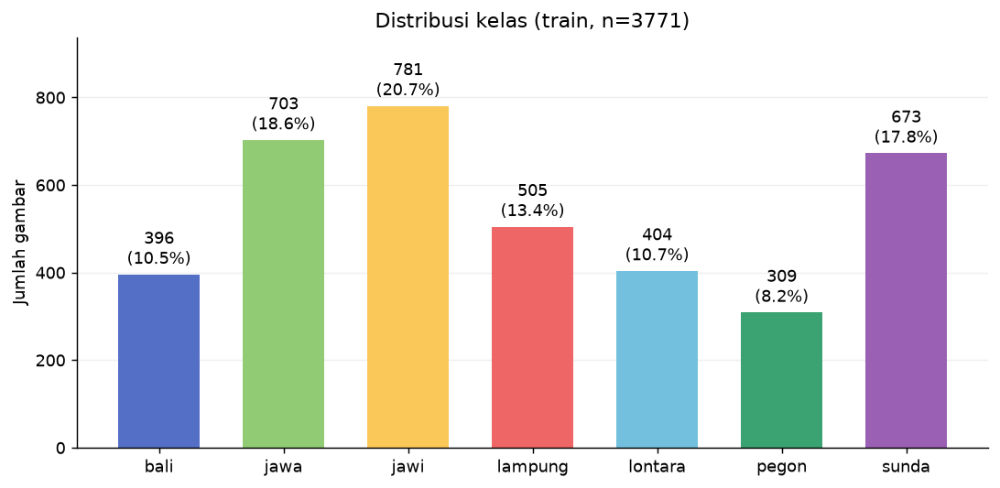

In [7]:
eda_fig, eda_ax = plt.subplots(figsize=(8.5, 4.2))
eda_bars = eda_ax.bar(EDA_LABELS, eda_label_counts.to_numpy(),
                      color=[EDA_COLORS[c] for c in EDA_LABELS], width=0.65)
eda_ax.bar_label(eda_bars, labels=[f'{n}\n({100 * n / len(eda_train):.1f}%)' for n in eda_label_counts], padding=3)
eda_ax.set(title=f'Distribusi kelas (train, n={len(eda_train)})', ylabel='Jumlah gambar',
           ylim=(0, eda_label_counts.max() * 1.2))
eda_ax.yaxis.grid(alpha=0.2)
eda_ax.set_axisbelow(True)
eda_fig.tight_layout()
plt.show()

## [4.3] Baseline 0: tebakan kelas mayoritas

Batas bawah metrik: menebak Jawi (kelas terbanyak) untuk semua gambar.

In [8]:
eda_y = eda_train.label.to_numpy()
eda_majority = pd.Series(eda_y).mode()[0]
print(f'Baseline 0 (selalu {eda_majority}): macro F1 = {f1_score(eda_y, np.full(len(eda_y), eda_majority), average="macro"):.4f}')

Baseline 0 (selalu jawi): macro F1 = 0.0490


**Observation**

> Pegon paling sedikit (309, 8,2%), Jawi paling banyak (781, 20,7%); rasio 2,5x.

**Modelling consequence**

> Loss memakai bobot kelas 1/sqrt(n), cukup untuk menaikkan Pegon tanpa membuat model terlalu sering menebak kelas kecil (bobot 1/n penuh diuji dan ditolak, lihat Bagian 11).

---

# EDA dengan Konsekuensi Pemodelan <a name="5"></a>

---

Setiap temuan ditulis dalam format yang sama: observasi, bukti, interpretasi, dan konsekuensinya pada pemodelan. Hanya temuan yang mengubah keputusan yang ditampilkan.

## [5.1] Observation: page langka di train tetapi seperempat test

### Evidence

,train_%,test_%,train_n,test_n
kind,,,,
line,75.1,58.3,2832,711
block,14.1,15.2,530,185
glyph,5.6,2.0,210,24
page,5.3,24.6,199,300


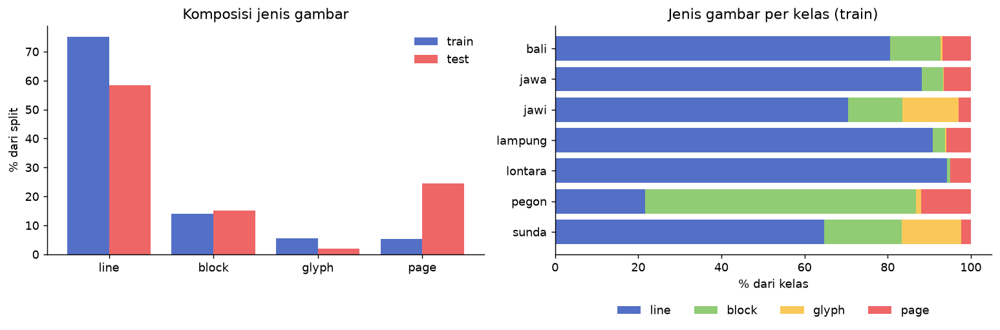

In [9]:
def eda_kind(size):
    w, h = size
    if h >= 250:
        return 'page'
    if w / h >= 2:
        return 'line'
    return 'glyph' if max(w, h) < 64 else 'block'


eda_train['w'], eda_train['h'] = zip(*[Image.open(p).size for p in eda_train.path])
eda_test['w'], eda_test['h'] = zip(*[Image.open(p).size for p in eda_test.path])
eda_train['kind'] = [eda_kind(s) for s in zip(eda_train.w, eda_train.h)]
eda_test['kind'] = [eda_kind(s) for s in zip(eda_test.w, eda_test.h)]
eda_kind_table = pd.DataFrame({
    'train_%': (100 * eda_train.kind.value_counts(normalize=True)).round(1),
    'test_%': (100 * eda_test.kind.value_counts(normalize=True)).round(1),
    'train_n': eda_train.kind.value_counts(),
    'test_n': eda_test.kind.value_counts(),
}).reindex(['line', 'block', 'glyph', 'page'])
display(eda_kind_table)

eda_fig, eda_axes = plt.subplots(1, 2, figsize=(12, 4.2))
eda_x = np.arange(4)
eda_axes[0].bar(eda_x - 0.2, eda_kind_table['train_%'], 0.4, label='train', color='#5470C6')
eda_axes[0].bar(eda_x + 0.2, eda_kind_table['test_%'], 0.4, label='test', color='#EE6666')
eda_axes[0].set_xticks(eda_x, eda_kind_table.index)
eda_axes[0].set(title='Komposisi jenis gambar', ylabel='% dari split')
eda_axes[0].legend(frameon=False)
eda_ct = pd.crosstab(eda_train.label, eda_train.kind, normalize='index').reindex(EDA_LABELS)[['line', 'block', 'glyph', 'page']]
eda_left = np.zeros(len(EDA_LABELS))
for kind in eda_ct.columns:
    eda_axes[1].barh(EDA_LABELS, eda_ct[kind] * 100, left=eda_left, color=EDA_KIND_COLORS[kind], label=kind)
    eda_left += eda_ct[kind].to_numpy() * 100
eda_axes[1].invert_yaxis()
eda_axes[1].set(title='Jenis gambar per kelas (train)', xlabel='% dari kelas')
eda_axes[1].legend(frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.32))
eda_fig.tight_layout()
plt.show()

Histogram tinggi citra (skala log) dan rasio aspek, train dibanding test. Garis putus-putus menandai batas page 250 piksel dan batas baris rasio 2.

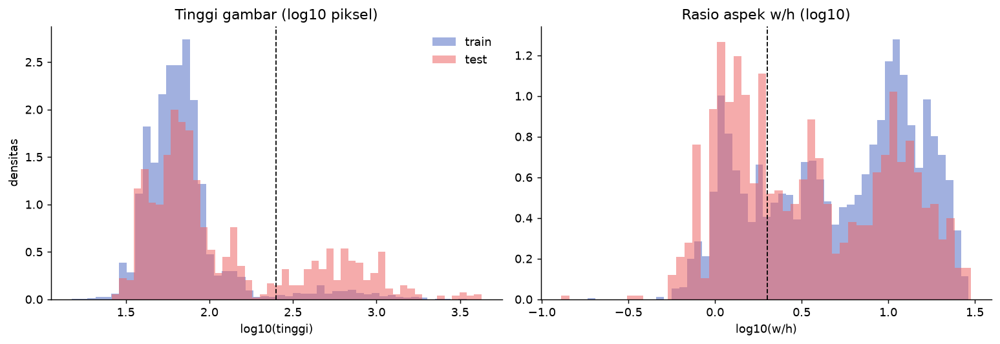

Median tinggi train/test: 64 / 76
Median rasio aspek baris train/test: 9.6 / 8.5


In [10]:
eda_fig, eda_axes = plt.subplots(1, 2, figsize=(12, 4.2))
for eda_frame, eda_name, eda_color in [(eda_train, 'train', '#5470C6'), (eda_test, 'test', '#EE6666')]:
    eda_axes[0].hist(np.log10(eda_frame.h), bins=50, alpha=0.55, color=eda_color, density=True, label=eda_name)
    eda_axes[1].hist(np.log10(eda_frame.w / eda_frame.h), bins=50, alpha=0.55, color=eda_color, density=True, label=eda_name)
eda_axes[0].axvline(np.log10(250), color='black', lw=1, ls='--')
eda_axes[0].set(title='Tinggi gambar (log10 piksel)', xlabel='log10(tinggi)', ylabel='densitas')
eda_axes[1].axvline(np.log10(2), color='black', lw=1, ls='--')
eda_axes[1].set(title='Rasio aspek w/h (log10)', xlabel='log10(w/h)')
eda_axes[0].legend(frameon=False)
eda_fig.tight_layout()
plt.show()
print('Median tinggi train/test:', int(eda_train.h.median()), '/', int(eda_test.h.median()))
print('Median rasio aspek baris train/test:',
      round(float((eda_train.w / eda_train.h)[eda_train.kind == 'line'].median()), 1), '/',
      round(float((eda_test.w / eda_test.h)[eda_test.kind == 'line'].median()), 1))

### Interpretation

> Page 199 citra (5,3%) di train dan 300 (24,6%) di test. Batas 250 piksel jatuh di lembah antara dua kelompok tinggi, jadi routing page stabil. Pada pipeline v2 page ikut di-letterbox ke 160x640 dan hanya mengisi 33% kanvas, huruf menjadi sekitar 3,5 piksel.

### Hypothesis

> Membaca page pada 640x640 akan menaikkan akurasi page tanpa mengganggu baris.

### Planned experiment

> Experiment 2 (v5): view page 640x640, fold dan resep lain identik v2.

### Evidence visual: baris train dan page train

Dua baris dan dua page acak per kelas, rasio asli dipertahankan.

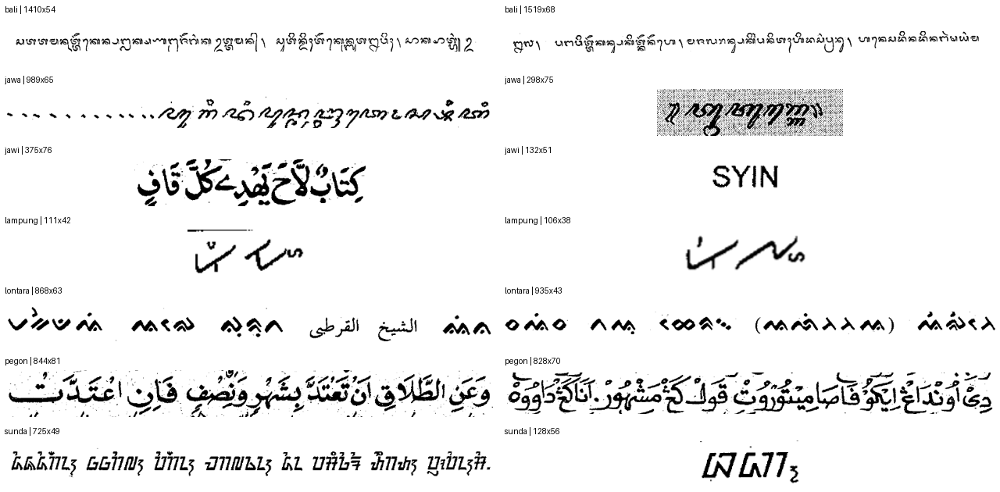

In [11]:
def eda_sheet(frame, columns, tile, title_fn):
    rows = (len(frame) + columns - 1) // columns
    width, height = tile
    canvas = Image.new('RGB', (columns * width, rows * height), 'white')
    draw = ImageDraw.Draw(canvas)
    for index, row in enumerate(frame.itertuples(index=False)):
        x, y = index % columns * width, index // columns * height
        with Image.open(row.path) as image:
            preview = ImageOps.contain(image.convert('RGB'), (width - 12, height - 30))
        canvas.paste(preview, (x + (width - preview.width) // 2, y + 24 + (height - 30 - preview.height) // 2))
        draw.text((x + 6, y + 6), title_fn(row), fill='black')
    display(canvas)


eda_sample = (eda_train[eda_train.kind == 'line'].groupby('label', group_keys=False)
              .sample(n=2, random_state=EDA_SEED).sort_values('label'))
eda_sheet(eda_sample, columns=2, tile=(640, 90), title_fn=lambda r: f'{r.label} | {r.w}x{r.h}')

**Observation**

> Baris train adalah pindaian buku: tinta hitam di atas putih, tepi bersih. Beberapa baris memuat kata dari aksara lain (kata Arab di baris Lontara, huruf Latin di Jawi), jadi label mengikuti sumber buku, bukan setiap huruf. Karena itu logit tile dirata-ratakan per gambar.

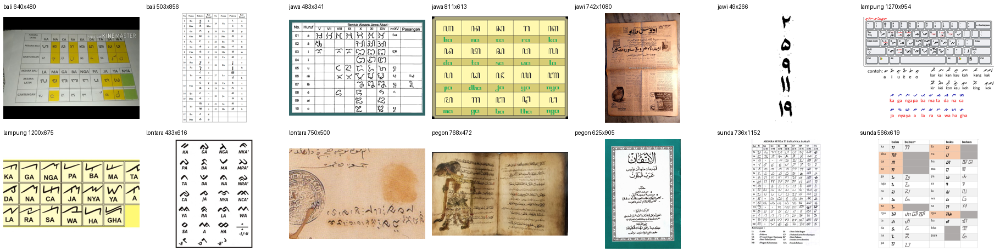

In [12]:
eda_pages = (eda_train[eda_train.kind == 'page'].groupby('label', group_keys=False)
             .sample(n=2, random_state=EDA_SEED).sort_values('label'))
eda_sheet(eda_pages, columns=7, tile=(260, 230), title_fn=lambda r: f'{r.label} {r.w}x{r.h}')

**Observation**

> Page adalah foto web berwarna: tabel aksara, kartu belajar, foto naskah. Label mengikuti topik gambar, sehingga tabel berisi beberapa aksara ambigu secara bawaan.

**Modelling consequence**

> Page tidak dibinarisasi dan tidak dikorupsi seperti baris (page test bersih); augmentasinya hanya foto ringan yang dikalibrasi.

## [5.2] Observation: baris test terkorupsi, baris train bersih

### Evidence

,saturasi,ketajaman,porsi_tinta
split,,,
test,10.241,0.32,0.191
train,0.000,0.47,0.142


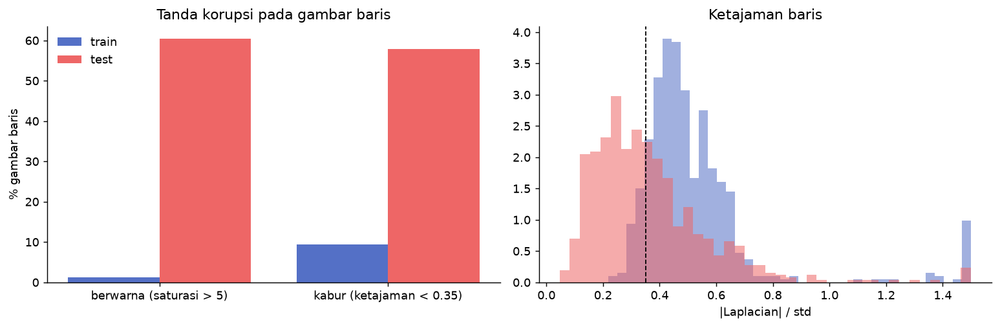

Baris berwarna: train 1.2% | test 60.5%
Baris kabur   : train 9.3% | test 57.9%


In [13]:
def eda_image_stats(path):
    rgb = np.asarray(Image.open(path).convert('RGB'), dtype=np.float32)
    gray = rgb.mean(2)
    sat = (rgb.max(2) - rgb.min(2)).mean()
    lap = ndimage.laplace(gray)
    sharp = float(np.abs(lap).mean() / (gray.std() + 1e-6))
    ink = gray < min(128, np.percentile(gray, 50))
    return sat, sharp, float(ink.mean())


eda_line_tr = eda_train[eda_train.kind == 'line'].sample(600, random_state=EDA_SEED)
eda_line_te = eda_test[eda_test.kind == 'line']
eda_stats = pd.concat([
    pd.DataFrame([eda_image_stats(p) for p in eda_line_tr.path], columns=['saturasi', 'ketajaman', 'porsi_tinta']).assign(split='train'),
    pd.DataFrame([eda_image_stats(p) for p in eda_line_te.path], columns=['saturasi', 'ketajaman', 'porsi_tinta']).assign(split='test'),
])
display(eda_stats.groupby('split').median().round(3))
eda_flags = (eda_stats.assign(berwarna=eda_stats.saturasi > 5, kabur=eda_stats.ketajaman < 0.35)
             .groupby('split')[['berwarna', 'kabur']].mean().reindex(['train', 'test']) * 100)
eda_fig, eda_axes = plt.subplots(1, 2, figsize=(12, 4))
eda_x = np.arange(2)
eda_axes[0].bar(eda_x - 0.2, eda_flags.loc['train'], 0.4, color='#5470C6', label='train')
eda_axes[0].bar(eda_x + 0.2, eda_flags.loc['test'], 0.4, color='#EE6666', label='test')
eda_axes[0].set_xticks(eda_x, ['berwarna (saturasi > 5)', 'kabur (ketajaman < 0.35)'])
eda_axes[0].set(title='Tanda korupsi pada gambar baris', ylabel='% gambar baris')
eda_axes[0].legend(frameon=False)
for eda_split, eda_color in [('train', '#5470C6'), ('test', '#EE6666')]:
    s = eda_stats[eda_stats.split == eda_split]
    eda_axes[1].hist(s.ketajaman.clip(0, 1.5), bins=40, alpha=0.55, density=True, color=eda_color, label=eda_split)
eda_axes[1].axvline(0.35, color='black', lw=1, ls='--')
eda_axes[1].set(title='Ketajaman baris', xlabel='|Laplacian| / std')
eda_fig.tight_layout()
plt.show()
print(f'Baris berwarna: train {eda_flags.loc["train", "berwarna"]:.1f}% | test {eda_flags.loc["test", "berwarna"]:.1f}%')
print(f'Baris kabur   : train {eda_flags.loc["train", "kabur"]:.1f}% | test {eda_flags.loc["test", "kabur"]:.1f}%')

Delapan baris test acak, sebagai pembanding langsung galeri baris train di Bagian 5.1.

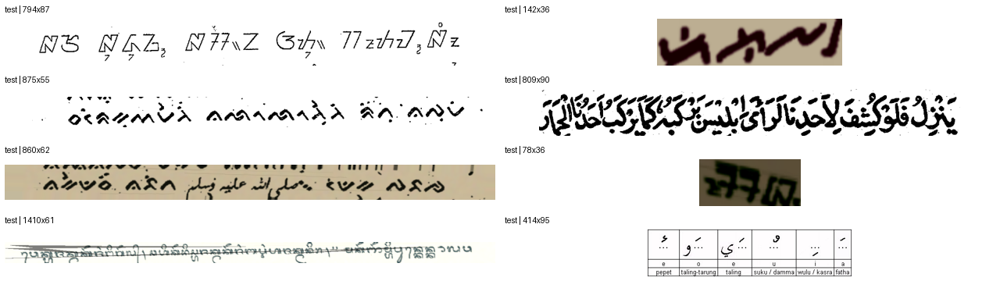

In [14]:
eda_test_lines = eda_test[eda_test.kind == 'line'].sample(8, random_state=EDA_SEED)
eda_sheet(eda_test_lines, columns=2, tile=(640, 90), title_fn=lambda r: f'test | {r.w}x{r.h}')

### Interpretation

> Baris test berwarna 60,5% dan kabur 57,9%, sedangkan train 1,2% dan 9,3%. Korupsi yang terlihat: latar kekuningan, tinta berwarna, blur, poligon abu, kotak hitam, rotasi. Train adalah pindaian hitam di atas putih, test adalah versi yang sudah dirusak.

### Hypothesis

> Korupsi test dibuat pada citra mentah, lalu model membaca hasil preprocessing. Jika korupsi sintetis diterapkan SEBELUM preprocessing saat training, model melihat distribusi yang sama dengan test.

### Planned experiment

> Experiment 1 (v2): `corrupt()` sebelum `preprocess()`, validasi pada view terkorupsi dengan seed tetap per citra.

## [5.3] Observation: Jawi dan Pegon

### Evidence

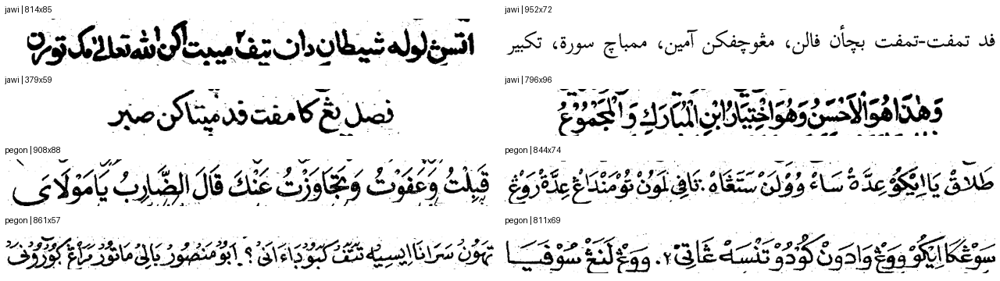

In [15]:
eda_jp = (eda_train[(eda_train.kind == 'line') & eda_train.label.isin(['jawi', 'pegon'])]
          .groupby('label', group_keys=False).sample(n=4, random_state=EDA_SEED + 1).sort_values('label'))
eda_sheet(eda_jp, columns=2, tile=(640, 90), title_fn=lambda r: f'{r.label} | {r.w}x{r.h}')

### Interpretation

> Bentuk hurufnya identik; bedanya bahasa (Melayu vs Jawa). Harakat penuh lebih sering pada Pegon, tetapi tidak mutlak.

### Consequence

> Tidak ada preprocessing yang bisa memisahkan keduanya. Pasangan ini diukur terpisah di error analysis, dan setiap perubahan pipeline dicek apakah merusaknya.

## [5.4] Observation: baris sangat panjang

> Median rasio aspek baris 9,6 (train) dan 8,5 (test). Memperkecil baris ke kotak menghancurkan huruf.

**Consequence**

> Baris dibaca pada tinggi tetap 160 piksel: jendela acak 640 saat training, tile setengah tumpang yang logit-nya dirata-ratakan saat evaluasi.

## [5.5] Ringkasan EDA

| Temuan | Keputusan |
|---|---|
| Test terkorupsi, train bersih | `corrupt()` sebelum preprocessing (v2) |
| Page langka dan kecil di kanvas | View page 640x640 (v5), porsi 20% micro-batch |
| Baris sangat panjang | Tinggi tetap 160, jendela/tile 640 |
| Format berkas berbeda | Bukan fitur; JPEG jadi augmentasi |
| Jawi/Pegon beda bahasa | Dipantau khusus |

---

# Strategi Validasi <a name="6"></a>

---

## [6.1] Apa yang harus disimulasikan validasi?

Unit independen di test adalah **potongan dari sumber yang tidak dilihat model**. Near-duplicate di train (baris yang sama dipotong dua kali, atau gambar yang di-encode ulang) akan membuat skor validasi naik semu bila tersebar ke train dan validasi. v1 memakai holdout acak: OOF 0,976 tetapi LB 0,863.

Kode berikut membangun ulang grup duplikat dari piksel (hash perseptual) dan embedding DINOv3-S, lalu memastikan partisinya identik dengan `folds.csv` yang dipakai v2 dan v5.

In [16]:
train = pd.read_csv(CFG.DATA_DIR / 'train.csv')
test = pd.read_csv(CFG.DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
if CFG.SMOKE_TEST:
    train = train.sample(600, random_state=CFG.SEED).reset_index(drop=True)
    test = test.sample(120, random_state=CFG.SEED).reset_index(drop=True)
train['path'] = [str(CFG.DATA_DIR / 'images' / 'train' / i) for i in train.image_id]
test['path'] = [str(CFG.DATA_DIR / 'images' / 'test' / i) for i in test.image_id]
print(f'Train: {len(train)} | Test: {len(test)}')

Train: 3771 | Test: 1220


## [6.2] Unit independen dan grup duplikat

Train berisi banyak salinan dari citra yang sama: disalin ulang, dipindai ulang, diwarnai, atau dipotong sedikit berbeda. Jika dua salinan terbagi ke train dan validasi, model cukup mengingat salinannya dan skor validasi naik semu. Grup duplikat dibentuk dalam dua tahap, sama seperti yang dipakai v5.

### [6.2.1] Tahap 1: hash persepsi

Setiap citra dinormalkan (gray, kontras 2-98 persen, polaritas tinta gelap, crop ke tinta), lalu diberi pHash dan dHash 64 bit. Pasangan dengan jarak Hamming paling banyak 10 dari 128 bit dan rasio aspek mirip (|log rasio| < 0,25) digabung, begitu pula citra dengan piksel identik.

In [17]:
def open_rgb(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        if im.mode in ('RGBA', 'LA', 'P', 'PA'):
            im = im.convert('RGBA')
            bg = Image.new('RGBA', im.size, 'white')
            im = Image.alpha_composite(bg, im)
        return im.convert('RGB')


def norm_view(path):
    g = np.asarray(open_rgb(path).convert('L'), dtype=np.float32)
    lo, hi = np.percentile(g, [2, 98])
    g = np.clip((g - lo) / max(hi - lo, 1), 0, 1)
    if g.mean() < 0.5:
        g = 1 - g
    ink = g < 0.5
    ys, xs = np.where(ink)
    if len(ys) > 10:
        g = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    return g


def phash(g, size=8, hi=32):
    im = Image.fromarray((g * 255).astype(np.uint8)).resize((hi, hi), Image.Resampling.BILINEAR)
    d = dctn(np.asarray(im, dtype=np.float32), norm='ortho')[:size, :size]
    return (d > np.median(d[1:, 1:] if size > 1 else d)).ravel()


def dhash(g, size=8):
    im = np.asarray(Image.fromarray((g * 255).astype(np.uint8)).resize((size + 1, size), Image.Resampling.BILINEAR), dtype=np.int16)
    return (im[:, 1:] > im[:, :-1]).ravel()


def dup_hashes(path):
    im = open_rgb(path)
    pix = hashlib.md5(np.asarray(im.convert('L')).tobytes() + str(im.size).encode()).hexdigest()
    g = norm_view(path)
    return pix, np.concatenate([phash(g), dhash(g)]), g.shape[1] / max(g.shape[0], 1)


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, a):
        while self.p[a] != a:
            self.p[a] = self.p[self.p[a]]
            a = self.p[a]
        return a

    def union(self, a, b):
        self.p[self.find(a)] = self.find(b)

Train dan test digabung dalam tabel `frames`, lalu setiap citra di-hash. Pasangan dengan jarak Hamming paling banyak 10 dari 128 bit dan rasio aspek serupa digabung dengan union-find, begitu pula citra dengan MD5 piksel sama.

In [18]:
frames = pd.concat([train[['image_id', 'label', 'path']].assign(split='train'),
                    test[['image_id', 'path']].assign(split='test')], ignore_index=True)
with Pool(CFG.WORKERS) as pool:
    hash_res = pool.map(dup_hashes, list(frames.path), chunksize=16)
frames['pix_md5'] = [r[0] for r in hash_res]
hash_bits = np.stack([r[1] for r in hash_res]).astype(np.uint8)
hash_ar = np.array([r[2] for r in hash_res])

n_all = len(frames)
near_pairs = []
for s in range(0, n_all, 512):
    blk = (hash_bits[s:s + 512, None, :] != hash_bits[None, :, :]).sum(-1)
    gate = np.abs(np.log(hash_ar[s:s + 512, None] / hash_ar[None, :])) < 0.25
    for a in range(blk.shape[0]):
        blk[a, s + a] = 999
    blk = np.where(gate, blk, 999)
    ii, jj = np.where(blk <= 10)
    near_pairs += [(s + i, j) for i, j in zip(ii, jj) if s + i < j]

uf_hash = UnionFind(n_all)
for i, j in near_pairs:
    uf_hash.union(i, j)
for _, idx in frames.groupby('pix_md5').groups.items():
    idx = list(idx)
    for a in idx[1:]:
        uf_hash.union(idx[0], a)
frames['hash_group'] = [uf_hash.find(i) for i in range(n_all)]
print(f'Pasangan near-duplicate hash: {len(near_pairs)} | grup hash: {frames.hash_group.nunique()} dari {n_all} citra')

Pasangan near-duplicate hash: 30 | grup hash: 4962 dari 4991 citra


### [6.2.2] Tahap 2: embedding lalu verifikasi piksel

Hash melewatkan salinan yang dipindai ulang atau diwarnai. Embedding DINOv3 ViT-S dari view ternormal dipakai untuk mencari 10 tetangga terdekat. Kosinus mentah tidak berguna karena semua baris teks tampak mirip (sekitar 0,97), sehingga embedding dikurangi rata-ratanya dulu. Tetangga hanya kandidat; pasangan disebut duplikat bila korelasi piksel view kecil 32x160 (dengan geser horizontal hingga 3 piksel) cukup tinggi: minimal 0,5 untuk pasangan train-train dan 0,8 untuk pasangan lain. Pengelompokan berlebih aman untuk CV, pengelompokan kurang justru bocor.

In [19]:
DUP_S, DUP_K, PH, PW = 224, 10, 32, 160


def dup_views(path):
    g = norm_view(path)
    u8 = Image.fromarray((g * 255).astype(np.uint8))
    lb = u8.copy()
    lb.thumbnail((DUP_S, DUP_S), Image.Resampling.BICUBIC)
    c = Image.new('L', (DUP_S, DUP_S), 255)
    c.paste(lb, ((DUP_S - lb.width) // 2, (DUP_S - lb.height) // 2))
    small = np.asarray(u8.resize((PW, PH), Image.Resampling.BOX), dtype=np.float32)
    return np.asarray(c), small, g.shape[1] / max(g.shape[0], 1)


def pixcorr(a, b, shift=3):
    best = -1.0
    for dx in range(-shift, shift + 1):
        x, y = (a[:, dx:], b[:, :PW - dx]) if dx >= 0 else (a[:, :PW + dx], b[:, -dx:])
        x = x - x.mean()
        y = y - y.mean()
        best = max(best, float((x * y).sum() / (np.sqrt((x * x).sum() * (y * y).sum()) + 1e-6)))
    return best


with Pool(CFG.WORKERS) as pool:
    dv = pool.map(dup_views, list(frames.path), chunksize=16)
dup_small = np.stack([v[1] for v in dv])
dup_ar = np.array([v[2] for v in dv])
dup_x = np.stack([v[0] for v in dv])

dup_model = timm.create_model(CFG.DUP_BACKBONE, pretrained=True, num_classes=0).eval()
torch.set_num_threads(20)
dup_mean = torch.tensor([.485, .456, .406]).view(1, 3, 1, 1)
dup_std = torch.tensor([.229, .224, .225]).view(1, 3, 1, 1)
dup_emb = []
with torch.inference_mode():
    for s in range(0, len(dup_x), 64):
        x = torch.from_numpy(dup_x[s:s + 64]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
        dup_emb.append(dup_model((x - dup_mean) / dup_std))
dup_emb = torch.nn.functional.normalize(torch.cat(dup_emb), dim=1).numpy()
del dup_model, dup_x
gc.collect()

is_tr = (frames.split == 'train').values
ec = dup_emb - dup_emb[is_tr].mean(0)
ec /= np.linalg.norm(ec, axis=1, keepdims=True)
sim = ec @ ec.T
np.fill_diagonal(sim, -1)
topk = np.argsort(-sim, axis=1)[:, :DUP_K]
rows = []
for i in range(n_all):
    for j in topk[i]:
        if i < j or i not in topk[j]:
            a, b = (i, j) if i < j else (j, i)
            if abs(np.log(dup_ar[a] / dup_ar[b])) < 0.3:
                rows.append((a, b, float(sim[a, b])))
pairs = pd.DataFrame(rows, columns=['i', 'j', 'emb']).drop_duplicates(['i', 'j'])
pairs['pix'] = [pixcorr(dup_small[a], dup_small[b]) for a, b in zip(pairs.i, pairs.j)]
pairs['train_train'] = is_tr[pairs.i.values] & is_tr[pairs.j.values]
dup_pairs = pairs[(pairs.train_train & (pairs.pix >= 0.50)) | (pairs.pix >= 0.80)]

uf = UnionFind(n_all)
for a, b in zip(dup_pairs.i, dup_pairs.j):
    uf.union(a, b)
for _, idx in frames.groupby('hash_group').groups.items():
    idx = list(idx)
    for a in idx[1:]:
        uf.union(idx[0], a)
frames['dup_group'] = [uf.find(i) for i in range(n_all)]
frames['dup_group_size'] = frames.dup_group.map(frames.dup_group.value_counts())
del sim, ec
print(f'Kandidat pasangan: {len(pairs)} | duplikat terverifikasi: {len(dup_pairs)}')

Kandidat pasangan: 28379 | duplikat terverifikasi: 307


### [6.2.3] Hasil pengelompokan

Tabel merangkum berapa citra train yang punya salinan, berapa grup yang labelnya bercampur, dan berapa citra test yang merupakan salinan citra train.

,nilai
grup di train,3560
citra train dalam grup > 1,312
grup terbesar,42
grup train berlabel campur,2
citra test bersalinan di train,17


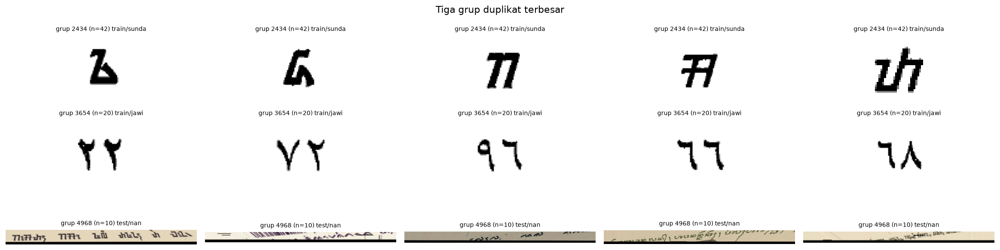

In [20]:
tr_frames = frames[frames.split == 'train']
mixed = tr_frames.groupby('dup_group').label.nunique()
dup_summary = pd.DataFrame({
    'nilai': [
        tr_frames.dup_group.nunique(),
        int((tr_frames.groupby('dup_group').image_id.transform('size') > 1).sum()),
        int(frames.dup_group_size.max()),
        int((mixed > 1).sum()),
        int(frames[(frames.split == 'test') & frames.dup_group.isin(set(tr_frames.dup_group))].shape[0]),
    ]}, index=['grup di train', 'citra train dalam grup > 1', 'grup terbesar',
              'grup train berlabel campur', 'citra test bersalinan di train'])
display(dup_summary)

big = frames.dup_group.value_counts().index[:3]
fig, axes = plt.subplots(3, 5, figsize=(18, 5))
for r, gid in enumerate(big):
    mem = frames[frames.dup_group == gid].head(5)
    for c in range(5):
        axes[r, c].axis('off')
    for c, m in enumerate(mem.itertuples()):
        axes[r, c].imshow(open_rgb(m.path))
        axes[r, c].set_title(f'grup {gid} (n={m.dup_group_size}) {m.split}/{m.label}', fontsize=8)
fig.suptitle('Tiga grup duplikat terbesar')
fig.tight_layout()
plt.show()

#### Insights

> Pada data penuh, 3.771 citra train terkumpul menjadi 3.560 grup; 312 citra (8,3%) punya salinan, dan grup terbesar berisi 42 citra. Tanpa grup, split acak menaruh salinan di kedua sisi dan skor validasi naik semu.

> Hanya 2 grup berlabel campur, keduanya kombinasi Jawi dan Pegon. Ini satu-satunya konflik label di data, konsisten dengan temuan EDA bahwa dua kelas ini sulit dipisahkan dari bentuk huruf. Sebanyak 17 citra test adalah salinan citra train dan semuanya hanya punya satu label.

## [6.3] Fold, bobot sampel, dan twins

Fold dibentuk dengan StratifiedGroupKFold 5 fold (shuffle, seed 42) pada `dup_group`, sehingga satu grup tidak pernah terbagi. Setiap citra diberi bobot 1/sqrt(ukuran grup) untuk sampler: grup 42 salinan dihitung sekitar 6,5 citra, bukan 42. Citra test yang satu grup dengan citra train berlabel tunggal dicatat sebagai twins; labelnya diambil dari train saat submission, sehingga tetap label train dan bukan pseudo label.

Hasilnya ditulis sebagai `folds.csv` dan `test_train_twins.csv` di folder data, karena dua berkas itu yang dibaca kode v2 dan v5 di Bagian 8 dan 9. Dengan begitu kode training tetap identik dengan run LB, tetapi seluruh proses berjalan dari notebook ini.

In [21]:
train = train.merge(frames.loc[frames.split == 'train', ['image_id', 'dup_group']], on='image_id', how='left')
train['fold'] = -1
sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=CFG.SEED)
for k, (_, va) in enumerate(sgkf.split(train, train.label, train.dup_group)):
    train.loc[va, 'fold'] = k
train['weight'] = 1 / np.sqrt(train.groupby('dup_group').image_id.transform('size'))
assert (train.groupby('dup_group').fold.nunique() == 1).all()
assert (train.fold >= 0).all()

te_frames = frames[frames.split == 'test']
tw = te_frames[te_frames.dup_group.isin(set(tr_frames.dup_group))].merge(
    tr_frames[['dup_group', 'label']].rename(columns={'label': 'train_label'}), on='dup_group')
twins_all = (tw.groupby('image_id').agg(train_label=('train_label', lambda s: s.mode()[0]),
                                        n_labels=('train_label', 'nunique')).reset_index())
twins = twins_all[twins_all.n_labels == 1]
if not CFG.SMOKE_TEST:
    # dibaca oleh kode v2 dan v5 di Bagian 8 dan 9
    train[['image_id', 'label', 'dup_group', 'fold', 'weight']].to_csv(CFG.DATA_DIR / 'folds.csv', index=False)
    twins_all.to_csv(CFG.DATA_DIR / 'test_train_twins.csv', index=False)

fold_share = pd.crosstab(train.fold, train.label, normalize='index')
fold_table = pd.DataFrame({
    'n_val': train.fold.value_counts().sort_index(),
    'n_train': len(train) - train.fold.value_counts().sort_index(),
    'maks_selisih_kelas_pp': ((fold_share - train.label.value_counts(normalize=True)).abs().max(axis=1) * 100).round(2),
})
display(fold_table)
print(f'Bobot efektif: {train.weight.sum():.0f} dari {len(train)} citra | twins test: {len(twins)}')

,n_val,n_train,maks_selisih_kelas_pp
fold,,,
0,754,3017,0.07
1,754,3017,0.11
2,755,3016,0.05
3,754,3017,0.07
4,754,3017,0.07


Bobot efektif: 3624 dari 3771 citra | twins test: 17


#### Insights

> Kelima fold berukuran 754 atau 755 citra dan porsi kelas tiap fold menyimpang paling banyak 0,11 poin persen dari porsi global. Stratifikasi tetap rapi walaupun grup tidak boleh dipecah.

> Bobot efektif 3.624 dari 3.771 citra: hanya 312 citra dalam grup duplikat yang bobotnya diturunkan. 17 citra test adalah salinan citra train berlabel tunggal (twins). Partisi grup, fold, dan twins ini identik 100% dengan yang dipakai run LB.

## [6.4] Checklist kebocoran

- [x] Grup duplikat tidak tersebar ke train dan validasi (diuji `assert` di atas).
- [x] Preprocessing tidak di-fit: semua operasi deterministik per citra, tanpa statistik dari validasi.
- [x] Seleksi epoch memakai skor validasi fold itu sendiri; prediksi test tidak ikut menentukan apa pun.
- [x] Tidak ada pseudo label, label propagation, atau data eksternal di training (aturan kompetisi 1 dan 4).
- [x] Embedding pengelompokan duplikat memakai train dan test tanpa label; label test tidak pernah dibaca.
- [ ] Batas yang diketahui: grup mengikuti kemiripan citra, bukan buku sumber. Riset tim mengukur kebocoran tingkat buku hanya sekitar 0,006 macro F1.

---

# Dekomposisi Masalah: Page dan Non-page <a name="7"></a>

---

### Motivation

Page dan non-page berbeda di hampir semua sumbu: sumber (foto web vs pindaian buku), korupsi (bersih vs terkorupsi), ukuran huruf di kanvas (3,5 px vs sekitar 30 px), dan porsi train vs test (5% vs 25%).

### Hypothesis

> Satu view untuk keduanya memaksa kompromi. Memberi page view sendiri akan menaikkan akurasi page, sedangkan non-page tetap dibaca dengan resep yang sudah terbukti.

### How to validate

> Kedua model dilatih pada fold identik. Page dinilai pada view bersih (page test bersih), non-page pada view terkorupsi dengan seed tetap. Model yang lebih baik per segmen dipakai untuk segmen itu (routing), bukan dirata-ratakan, supaya efek page bisa diisolasi di LB.

---

# Experiment 1: v2, Korupsi Sintetis untuk Non-page <a name="8"></a>

---

### Question

> Apakah meniru korupsi test sebelum preprocessing menutup gap train-test?

### Change from baseline (v1)

```text
v1: letterbox 160x640, tanpa augmentasi korupsi, holdout acak
+ corrupt() pada citra mentah sebelum preprocess (rotasi, tint, blur/pikselasi, poligon, dash, bar hitam, JPEG)
+ preprocess: hapus fill hitam, normalisasi polaritas dan kontras (Otsu), crop ke tinta
+ StratifiedGroupKFold 5 pada grup duplikat, bobot sampel 1/sqrt(ukuran grup)
```

Kode di bawah disalin dari `notebooks/v2.ipynb`.

## [8.1] Konfigurasi v2

In [22]:
def find_root():
    for c in [Path.cwd(), Path.cwd().parent, Path('/workspace/infest-26'), Path('/workspace')]:
        if (c / 'data/train.csv').exists():
            return c
    raise FileNotFoundError('data/train.csv tidak ditemukan - set ROOT manual')


ROOT = find_root()
DATA = ROOT / 'data'

SMOKE_TEST = False            # True: fold 0, 1 epoch
RUN_NAME = 'main'             # output + resume key: results/v2/<RUN_NAME>
SEED = 42
MODEL_NAME = 'vit_large_patch16_dinov3.lvd1689m'
H, W = 160, 640               # eda/07: tinggi tetap 160 -> tinta ~10 patch
EPOCHS, WARMUP_EPOCHS, PATIENCE = 12, 1, 4
MICRO_BATCH, ACCUM = 16, 2    # efektif 32; 5090 32GB muat tanpa grad checkpointing
EVAL_BATCH = 64
GRAD_CKPT = False             # True jika OOM
BASE_LR, HEAD_LR = 4e-5, 3e-4 # BASE_LR = blok teratas; blok bawah dikali LAYER_DECAY^depth
LAYER_DECAY, WEIGHT_DECAY = 0.85, 0.05
LABEL_SMOOTHING = 0.1
NONLINE_BOOST = 1.5           # prepro/03: non-line 41% test vs 21% train
FOLDS = [0, 1, 2, 3, 4]
NUM_WORKERS = min(16, os.cpu_count() or 4)
RAW_MAX_SIDE = 1600           # poster 5000px diperkecil sekali saat cache (canvas tetap 160 tinggi)
USE_TWINS = True              # 17 test near-copy train -> pakai label train
SAVE_WEIGHTS = False          # True: simpan state bf16 per fold (~600MB/fold)
LABELS = ['bali', 'jawa', 'jawi', 'lampung', 'lontara', 'pegon', 'sunda']
LABEL_TO_ID = {l: i for i, l in enumerate(LABELS)}
if SMOKE_TEST:
    EPOCHS, FOLDS, RUN_NAME = 1, [0], 'smoke'

assert torch.cuda.is_available(), 'Butuh GPU CUDA'
DEVICE = torch.device('cuda')
cap = torch.cuda.get_device_capability()
assert cap[0] < 12 or any(a.startswith('sm_12') for a in torch.cuda.get_arch_list()), \
    'torch ini tidak support RTX 5090 (sm_120): pip install -U torch torchvision --index-url https://download.pytorch.org/whl/cu128'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


seed_all(SEED)
OUT = ROOT / 'results' / 'v2' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
print(dict(root=str(ROOT), torch=torch.__version__, timm=timm.__version__, gpu=torch.cuda.get_device_name(),
           capability=cap, cpus=os.cpu_count(), workers=NUM_WORKERS, out=str(OUT)))

{'root': '/workspace/infest', 'torch': '2.8.0+cu128', 'timm': '1.0.27', 'gpu': 'NVIDIA GeForce RTX 5090', 'capability': (12, 0), 'cpus': 16, 'workers': 16, 'out': '/workspace/infest/results/v2/main'}


## [8.2] Pipeline preprocessing dan korupsi

Setiap angka di `corrupt()` berasal dari perbandingan statistik train dan test (docstring cell). Urutannya penting: korupsi pada RGB mentah, lalu preprocessing yang sama dengan test.

In [23]:
"""Preprocessing + augmentation for INFEST aksara classification. Import this from the training notebook.

Order matters:   raw RGB --(train only) corrupt()--> preprocess() --> to_canvas()
corrupt() BEFORE preprocess() because the test corruptions were applied to raw images; the network must
see train images that went through exactly the same normalisation the corrupted test images go through.

Every number below comes from eda/outputs (see eda/README.md):
  rotation +-15 deg          07: test |skew| p95=10, p99=13; 30% of test lines >=3 deg (train 4%)
  tint p=.45                 03: bg_sat>12 in 44% test vs 3% train
  blur/pixelate p=.55        03: sharp<0.6 in 69% test vs 12% train
  occluder p=.12, dashes .15 03 flat_gray 6.6% test (detector under-counts, seen in 02 zoom)
  black bar p=.07            03: black border 7.3% test vs 1.2% train
  jpeg p=.3                  01: JPEG 21% test vs 4.6% train
  canvas H=160 fixed height  07: letterbox 160x640 leaves bali/lontara at ~2 patches of ink
"""



# ----------------------------------------------------------------------------- load
def load_rgb(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        if im.mode in ("RGBA", "LA", "P", "PA"):
            im = im.convert("RGBA")
            im = Image.alpha_composite(Image.new("RGBA", im.size, "white"), im)
        return im.convert("RGB")


# ----------------------------------------------------------------------------- deterministic (train + test)
def _otsu(g):
    hist = np.bincount(g.ravel(), minlength=256).astype(float)
    p = hist / hist.sum(); w = np.cumsum(p); mu = np.cumsum(p * np.arange(256))
    return int(np.argmax((mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12)))


def remove_black_fill(g, dark=40, min_contact=0.3, min_solidity=0.9, max_holes=0.03):
    """Solid black regions glued to the border (shift / rotate fill, black bars) -> white.
    A border-touching pure-black component is fill when it has no holes (a real dark background has
    light text inside it) AND either (a) runs along >=min_contact of a side or (b) is near-convex
    (rotation corner triangle). Glyph-sized images (both sides <64px) only lose full-side bars.
    Only the thick core (survives 2px erosion) is removed, so thin strokes glued to the fill stay."""
    blk = g < dark
    if not blk.any():
        return g
    lab, n = ndi.label(blk)
    h, w = g.shape
    border = np.zeros_like(blk); border[0] = border[-1] = border[:, 0] = border[:, -1] = True
    tiny = max(h, w) < 64  # glyph-sized crops (e.g. a 20x20 bold numeral): only full-side bars count
    contact = 0.9 if tiny else min_contact
    objs = ndi.find_objects(lab)
    kill = set()
    for i in set(np.unique(lab[border & blk]).tolist()) - {0}:
        sl = objs[i - 1]
        comp = lab[sl] == i
        area = comp.sum()
        filled = ndi.binary_fill_holes(comp).sum()
        if (filled - area) / filled > max_holes or np.median(g[sl][comp]) > 15:
            continue
        run = max((lab[0] == i).sum() / w, (lab[-1] == i).sum() / w, (lab[:, 0] == i).sum() / h, (lab[:, -1] == i).sum() / h)
        if run >= contact:
            kill.add(i); continue
        if tiny or area < 0.005 * g.size:
            continue
        ys, xs = np.nonzero(comp)
        try:
            from scipy.spatial import ConvexHull
            hull = ConvexHull(np.c_[np.r_[ys, ys + 1, ys, ys + 1], np.r_[xs, xs, xs + 1, xs + 1]]).volume
        except Exception:
            continue
        if area / hull >= min_solidity:
            kill.add(i)
    if not kill:
        return g
    mask = np.isin(lab, list(kill))
    mask &= ndi.binary_dilation(ndi.binary_erosion(mask, iterations=2, border_value=1), iterations=3)
    out = g.copy()
    out[mask] = 255
    return out


def preprocess(rgb):
    """RGB PIL -> L PIL: gray, black fill removed, dark-ink-on-white, contrast normalised, cropped to ink.
    Fill removal runs BEFORE the polarity test: black rotation corners on a thin line can cover >50% of
    the frame and would otherwise flip the whole image to white-on-black (seen in debug_black_rotation.png)."""
    g = remove_black_fill(np.asarray(rgb.convert("L")))
    t = _otsu(g)
    if (g > t).mean() < 0.5:  # background is the majority class; if it is the dark side, invert
        g = 255 - g
    t = _otsu(g)
    ink, bg = g[g <= t], g[g > t]
    if ink.size and bg.size:
        lo, hi = np.percentile(ink, 10), np.median(bg)
        if hi - lo >= 20:  # skip blank / single-tone images
            g = np.clip((g.astype(np.float32) - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    return Image.fromarray(crop_to_ink(g))


def crop_to_ink(g, thr=128, trim=0.005, margin=0.08):
    ink = g < thr
    if ink.sum() < 20:
        return g
    def span(profile):
        c = np.cumsum(profile) / profile.sum()
        return int(np.searchsorted(c, trim)), int(np.searchsorted(c, 1 - trim))
    y0, y1 = span(ink.sum(1)); x0, x1 = span(ink.sum(0))
    if ink[y0:y1 + 1, x0:x1 + 1].mean() > 0.6:  # crop would be one solid blob (a black dash on a sparse page) -> keep all
        return g
    m = int(round(margin * max(y1 - y0, 8)))
    return g[max(0, y0 - m):y1 + m + 1, max(0, x0 - m):x1 + m + 1]


def to_canvas(img, H=160, W=640, train=False, rng=random):
    """Line-like crops (w/h>=2): resize to fixed height H, then random window (train) or tiles (eval).
    Others (posters, pages, square patches): letterbox. Returns list of HxW L images (len 1 when train)."""
    w, h = img.size
    if w / h >= 2:
        nw = max(1, round(w * H / h))
        img = img.resize((nw, H), Image.Resampling.BICUBIC if nw > w else Image.Resampling.LANCZOS)
        if nw <= W:
            c = Image.new("L", (W, H), 255); c.paste(img, ((W - nw) // 2, 0)); return [c]
        if train:
            x = rng.randint(0, nw - W); return [img.crop((x, 0, x + W, H))]
        n = math.ceil((nw - W) / (W // 2)) + 1
        xs = np.linspace(0, nw - W, n).round().astype(int)
        return [img.crop((x, 0, x + W, H)) for x in xs]
    s = min(H / h, W / w)
    img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.Resampling.BICUBIC if s > 1 else Image.Resampling.LANCZOS)
    c = Image.new("L", (W, H), 255); c.paste(img, ((W - img.width) // 2, (H - img.height) // 2)); return [c]


# ----------------------------------------------------------------------------- train-only test-like corruption
PARCHMENT = [(236, 224, 196), (222, 205, 170), (245, 238, 214), (210, 196, 160), (196, 186, 160), (250, 246, 230), (170, 170, 170), (230, 230, 230)]
INKS = [(20, 20, 20), (90, 20, 30), (30, 70, 40), (40, 40, 90), (70, 50, 30), (60, 30, 80)]


def rotate(img, angle, fill="edge"):
    """RandomRotation that mimics the test set: frame size kept, corners filled by edge-replicate / white / black."""
    if fill == "edge":
        a = np.asarray(img); pad = max(a.shape[:2]) // 2
        big = Image.fromarray(np.pad(a, ((pad, pad), (pad, pad), (0, 0)), mode="edge"))
        big = big.rotate(angle, resample=Image.Resampling.BICUBIC)
        return big.crop((pad, pad, pad + img.width, pad + img.height))
    color = (255, 255, 255) if fill == "white" else (0, 0, 0)
    return img.rotate(angle, resample=Image.Resampling.BICUBIC, fillcolor=color)


def _ink_mask(img):
    g = np.asarray(img.convert("L")); return g < min(_otsu(g), 128)


def ink_retained(img, angle):
    """Share of the ORIGINAL ink still inside the frame after rotation (fill can't fake it)."""
    m = Image.fromarray(_ink_mask(img).astype(np.uint8) * 255)
    return (np.asarray(m.rotate(angle, resample=Image.Resampling.NEAREST, fillcolor=0)) > 0).sum() / max((np.asarray(m) > 0).sum(), 1)


def corrupt(img, rng=random):
    """RGB PIL -> RGB PIL with test-like corruptions. Rotation angle is re-drawn while <60% of the ink stays in frame."""
    w, h = img.size
    if rng.random() < 0.5:
        for _ in range(4):
            angle = rng.uniform(-15, 15)
            if ink_retained(img, angle) >= 0.6:
                img = rotate(img, angle, rng.choice(["edge"] * 5 + ["white"] * 2 + ["black"])); break
    if rng.random() < 0.25 and w > 60:  # partial crop along the line
        cw, ch = int(w * rng.uniform(0.6, 1.0)), int(h * rng.uniform(0.85, 1.0))
        x, y = rng.randint(0, w - cw), rng.randint(0, h - ch)
        img = img.crop((x, y, x + cw, y + ch)); w, h = img.size
    if rng.random() < 0.45:  # tint: re-colour ink and paper
        g = np.asarray(img.convert("L"), dtype=np.float32)[..., None] / 255
        bg = np.array(rng.choice(PARCHMENT), dtype=np.float32) * rng.uniform(0.85, 1.05)
        ink = np.array(rng.choice(INKS), dtype=np.float32) + rng.uniform(0, 60)
        img = Image.fromarray(np.clip(ink * (1 - g) + bg * g, 0, 255).astype(np.uint8))
    if rng.random() < 0.45:
        if rng.random() < 0.5:
            img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0.3, 1.2) * max(h, 32) / 64))
        else:
            f = rng.uniform(0.35, 0.8)
            small = img.resize((max(4, int(w * f)), max(4, int(h * f))), Image.Resampling.BILINEAR)
            img = small.resize((w, h), rng.choice([Image.Resampling.NEAREST, Image.Resampling.BILINEAR, Image.Resampling.BICUBIC]))
    if rng.random() < 0.08:  # semi-transparent gray polygons
        over = Image.new("RGBA", img.size, (0, 0, 0, 0)); d = ImageDraw.Draw(over)
        for _ in range(rng.randint(1, 3)):
            v = rng.randint(60, 150)
            d.polygon([(rng.uniform(-.1, 1.1) * w, rng.uniform(-.1, 1.1) * h) for _ in range(3)], fill=(v, v, v, rng.randint(120, 230)))
        img = Image.alpha_composite(img.convert("RGBA"), over).convert("RGB")
    if rng.random() < 0.15:  # small black dashes / cutout
        d = ImageDraw.Draw(img)
        for _ in range(rng.randint(1, 4)):
            rw, rh = rng.uniform(.03, .1) * w, rng.uniform(.03, .1) * h + 1
            x, y = rng.uniform(0, w - rw), rng.uniform(0, h - rh)
            d.rectangle([x, y, x + rw, y + rh], fill=(0, 0, 0))
    if rng.random() < 0.07:  # black bar from a vertical shift
        a = np.asarray(img).copy(); k = int(h * rng.uniform(0.05, 0.25)) + 1
        if rng.random() < 0.5:
            a[:-k] = a[k:]; a[-k:] = 0
        else:
            a[k:] = a[:-k]; a[:k] = 0
        img = Image.fromarray(a)
    if rng.random() < 0.15:
        a = np.asarray(img, dtype=np.float32) + np.random.default_rng(rng.randint(0, 2**31)).normal(0, rng.uniform(5, 25), (h, w, 1))
        img = Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    if rng.random() < 0.3:
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=rng.randint(20, 75)); buf.seek(0)
        img = Image.open(buf).convert("RGB")
    return img


def train_view(path, rng=random, H=160, W=640):
    return to_canvas(preprocess(corrupt(load_rgb(path), rng)), H, W, train=True, rng=rng)[0]


def eval_views(path, H=160, W=640):
    return to_canvas(preprocess(load_rgb(path)), H, W, train=False)

# ---- self-check (same asserts as prepro/pipeline.py)
img = Image.new("RGB", (400, 60), "white"); ImageDraw.Draw(img).text((10, 20), "abc def ghi jkl", fill="black")
p = preprocess(img)
assert p.mode == "L" and p.width < 400 and np.asarray(p).min() == 0
inv = preprocess(ImageOps.invert(img))  # white-on-black must come out black-on-white
assert np.asarray(inv).mean() > 128
barred = np.asarray(img).copy(); barred[-15:] = 0
g = remove_black_fill(np.asarray(Image.fromarray(barred).convert("L")))
assert (g[-15:] == 255).all() and (g < 128).sum() > 0, "bar removed, text kept"
page = np.full((800, 600), 255, np.uint8); page[::40, ::40] = 180; page[400:410, 300:360] = 0
assert crop_to_ink(page).shape == page.shape, "sparse page + black dash must not collapse to the dash"
views = to_canvas(Image.new("L", (3000, 80), 255), train=False)
assert all(v.size == (640, 160) for v in views) and len(views) > 1
r = random.Random(0)
for _ in range(50):
    c = corrupt(img, r); assert c.mode == "RGB"
print("pipeline self-check OK")

pipeline self-check OK


## [8.3] Data, fold, twins, dan cache view evaluasi

In [24]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
sample_sub = pd.read_csv(DATA / 'sample_submission.csv')
assert set(train.label) == set(LABELS) and train.image_id.is_unique and test.image_id.is_unique
assert not set(train.image_id) & set(test.image_id)

folds_path = next((p for p in [DATA / 'folds.csv', ROOT / 'prepro/outputs/folds.csv'] if p.exists()), None)
assert folds_path is not None, 'folds.csv tidak ada: upload data/folds.csv (hasil prepro/05_make_folds.py)'
folds = pd.read_csv(folds_path)
assert set(folds.image_id) == set(train.image_id), 'folds.csv tidak cocok dengan train.csv'
train = train.merge(folds[['image_id', 'dup_group', 'fold', 'weight']], on='image_id', how='left')
assert (train.groupby('dup_group').fold.nunique() == 1).all(), 'dup_group bocor antar fold'

twins_path = next((p for p in [DATA / 'test_train_twins.csv', ROOT / 'prepro/outputs/test_train_twins.csv'] if p.exists()), None)
twins = pd.read_csv(twins_path) if twins_path else pd.DataFrame(columns=['image_id', 'train_label', 'n_labels'])
twins = twins[twins.image_id.isin(test.image_id) & (twins.n_labels == 1)]

train['path'] = [str(DATA / 'images/train' / i) for i in train.image_id]
test['path'] = [str(DATA / 'images/test' / i) for i in test.image_id]
y_all = train.label.map(LABEL_TO_ID).values
print('folds:', train.fold.value_counts().sort_index().to_dict(), '| twins:', len(twins))
display(pd.crosstab(train.label, train.fold))

folds: {0: 754, 1: 754, 2: 755, 3: 754, 4: 754} | twins: 17


fold,0,1,2,3,4
label,,,,,
bali,79,80,79,79,79
jawa,140,141,141,141,140
jawi,156,157,156,156,156
lampung,101,101,101,101,101
lontara,81,80,81,81,81
pegon,62,61,62,62,62
sunda,135,134,135,134,135


Semua citra dibaca sekali ke memori (sisi terpanjang maksimal 1.600 piksel) beserta hasil preprocess-nya. View validasi terkorupsi dibuat dengan seed tetap per citra, lalu dipotong menjadi tile 160x640 untuk evaluasi.

In [25]:
def load_cached(path):
    img = load_rgb(path)
    if max(img.size) > RAW_MAX_SIDE:
        img.thumbnail((RAW_MAX_SIDE, RAW_MAX_SIDE), Image.Resampling.LANCZOS)
    return np.asarray(img), np.asarray(preprocess(img))


def corrupted_val_pp(args):
    # val terkorupsi FIXED (seed per gambar) -> skor antar epoch/fold sebanding
    arr, j = args
    return np.asarray(preprocess(corrupt(Image.fromarray(arr), random.Random(f'val-{SEED}-{j}'))))


t0 = time.time()
with Pool(NUM_WORKERS) as pool:
    tr_cache = pool.map(load_cached, list(train.path), chunksize=16)
    te_cache = pool.map(load_cached, list(test.path), chunksize=16)
    train_raw = [a for a, _ in tr_cache]
    train_pp = [p for _, p in tr_cache]
    test_pp = [p for _, p in te_cache]
    del tr_cache, te_cache
    train_pp_cor = pool.map(corrupted_val_pp, [(a, j) for j, a in enumerate(train_raw)], chunksize=16)
print(f'cache {time.time() - t0:.0f}s')

nonline = np.array([p.shape[1] / p.shape[0] < 2 for p in train_pp])
test_nonline = np.array([p.shape[1] / p.shape[0] < 2 for p in test_pp])
print(f'non-line share: train {nonline.mean():.1%} | test {test_nonline.mean():.1%}')


def build_tiles(pps):
    tiles, owner = [], []
    for k, pp in enumerate(pps):
        for t in to_canvas(Image.fromarray(pp), H, W, train=False):
            tiles.append(np.asarray(t, dtype=np.uint8)); owner.append(k)
    return np.stack(tiles), np.array(owner)


clean_tiles, clean_owner = build_tiles(train_pp)
cor_tiles, cor_owner = build_tiles(train_pp_cor)
test_tiles, test_owner = build_tiles(test_pp)
del train_pp_cor
print('tiles train/cor/test:', len(clean_tiles), len(cor_tiles), len(test_tiles))

cache 11s
non-line share: train 22.7% | test 40.6%


tiles train/cor/test: 14682 13857 3429


## [8.4] Dataset dan pemeriksaan visual

Setiap kelas ditampilkan dalam empat tahap: mentah, kanvas bersih, view training, dan view validasi terkorupsi.

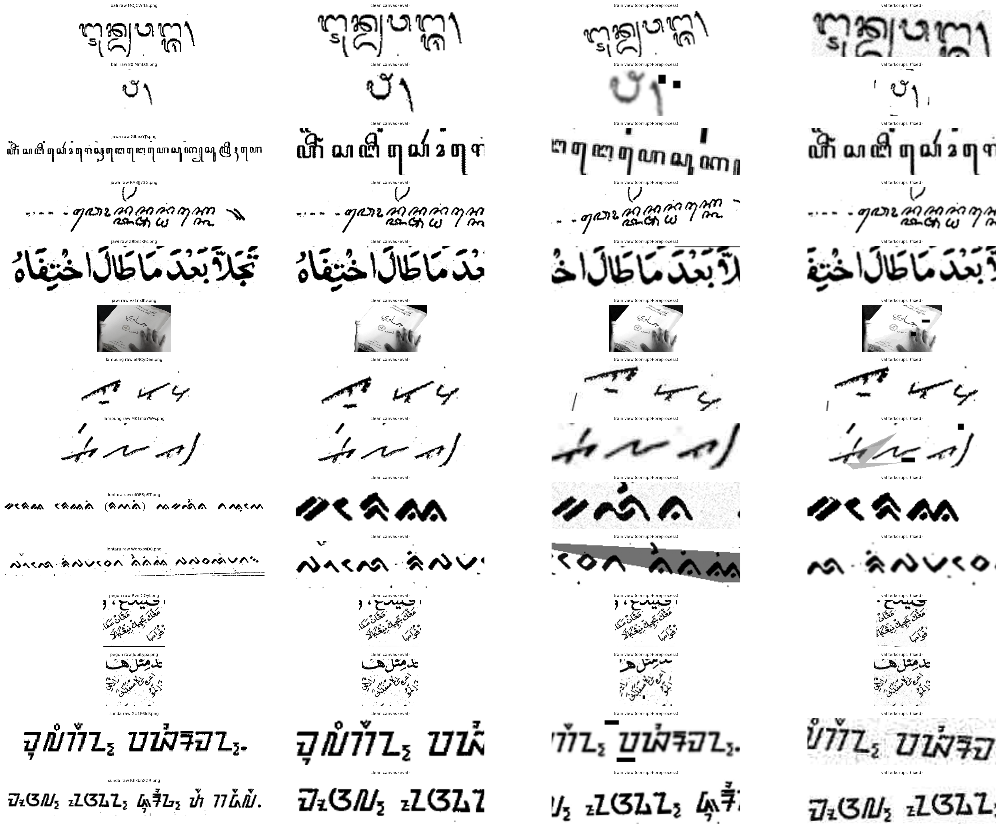

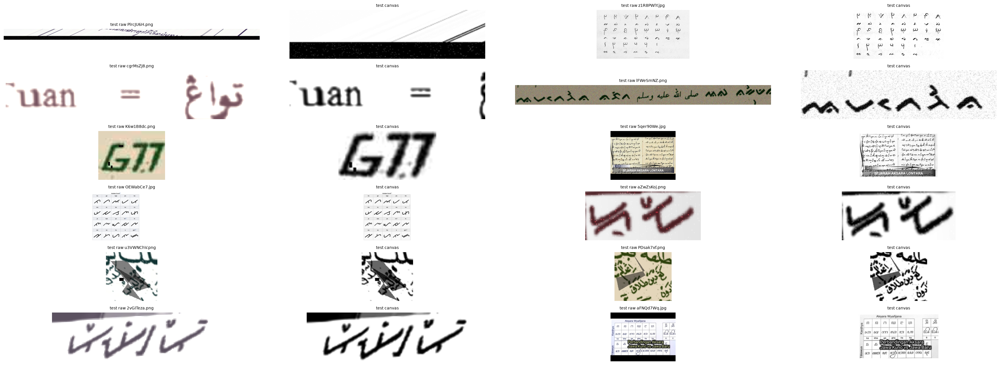

train clean  ink median=0.143  blank(<0.5%)=0.10%  >50% black=0.23%


val corrupt  ink median=0.144  blank(<0.5%)=0.14%  >50% black=0.55%
test         ink median=0.168  blank(<0.5%)=0.64%  >50% black=3.06%


In [26]:
MEAN_G = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD_G = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def gpu_norm(x):  # uint8 (B,1,H,W) -> normalised float (B,3,H,W)
    return (x.float().div_(255).expand(-1, 3, -1, -1) - MEAN_G) / STD_G


class TrainDS(Dataset):
    # corrupt -> preprocess -> random window. Seed = (SEED, epoch, image) -> reproducible at any num_workers
    def __init__(self, idx):
        self.idx, self.epoch = np.asarray(idx), 0

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = int(self.idx[i])
        rng = random.Random(f'{SEED}-{self.epoch}-{j}')
        v = to_canvas(preprocess(corrupt(Image.fromarray(train_raw[j]), rng)), H, W, train=True, rng=rng)[0]
        return torch.from_numpy(np.asarray(v, dtype=np.uint8).copy()).unsqueeze(0), int(y_all[j])


def subset_tiles(tiles, owner, idx):
    pos = {int(j): k for k, j in enumerate(idx)}
    m = np.isin(owner, idx)
    return tiles[m], np.array([pos[int(o)] for o in owner[m]])


@torch.inference_mode()
def predict_logits(model, tiles, owner, n):
    model.eval()
    out = torch.zeros(n, len(LABELS), dtype=torch.float64)
    cnt = torch.zeros(n, 1, dtype=torch.float64)
    for s in range(0, len(tiles), EVAL_BATCH):
        x = gpu_norm(torch.from_numpy(tiles[s:s + EVAL_BATCH]).to(DEVICE).unsqueeze(1))
        with torch.autocast('cuda', dtype=torch.bfloat16):
            lg = model(x).float().cpu().double()
        o = torch.from_numpy(owner[s:s + EVAL_BATCH]).long()
        out.index_add_(0, o, lg)
        cnt.index_add_(0, o, torch.ones(len(o), 1, dtype=torch.float64))
    assert (cnt > 0).all()
    return (out / cnt).numpy()


# visual check: per kelas raw | clean canvas | train view | val terkorupsi
ds_vis = TrainDS(np.arange(len(train)))
fig, axes = plt.subplots(len(LABELS) * 2, 4, figsize=(28, 3.2 * len(LABELS)))
for r, lab in enumerate(LABELS):
    for k, j in enumerate(train.index[train.label == lab].to_series().sample(2, random_state=r)):
        row = axes[2 * r + k]
        x, _ = ds_vis[j]
        row[0].imshow(train_raw[j]); row[0].set_title(f'{lab} raw {train.image_id[j]}', fontsize=8)
        row[1].imshow(clean_tiles[clean_owner == j][0], cmap='gray', vmin=0, vmax=255); row[1].set_title('clean canvas (eval)', fontsize=8)
        row[2].imshow(x[0], cmap='gray', vmin=0, vmax=255); row[2].set_title('train view (corrupt+preprocess)', fontsize=8)
        row[3].imshow(cor_tiles[cor_owner == j][0], cmap='gray', vmin=0, vmax=255); row[3].set_title('val terkorupsi (fixed)', fontsize=8)
        for a in row: a.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'samples_train.png', dpi=60); plt.show(); plt.close(fig)

fig, axes = plt.subplots(6, 4, figsize=(28, 10))
for a, j in zip(axes.ravel()[::2], test.sample(12, random_state=0).index):
    a.imshow(Image.open(test.path[j]).convert('RGB')); a.set_title(f'test raw {test.image_id[j]}', fontsize=8); a.axis('off')
for a, j in zip(axes.ravel()[1::2], test.sample(12, random_state=0).index):
    a.imshow(test_tiles[test_owner == j][0], cmap='gray', vmin=0, vmax=255); a.set_title('test canvas', fontsize=8); a.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'samples_test.png', dpi=60); plt.show(); plt.close(fig)

ink = lambda t: (t < 128).mean(axis=(1, 2))
for name, t in [('train clean', clean_tiles), ('val corrupt', cor_tiles), ('test', test_tiles)]:
    f = ink(t)
    print(f'{name:12s} ink median={np.median(f):.3f}  blank(<0.5%)={np.mean(f < .005):.2%}  >50% black={np.mean(f > .5):.2%}')
assert x.shape == (1, H, W) and x.dtype == torch.uint8

## [8.5] Model, optimizer, dan training per fold

In [27]:
def make_model():
    m = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABELS), img_size=(H, W), global_pool='token')
    if GRAD_CKPT:
        m.set_grad_checkpointing(True)
    return m.to(DEVICE)


def make_optimizer(model):
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    groups = param_groups_layer_decay(model, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY,
                                       no_weight_decay_list=model.no_weight_decay())
    for g in groups:
        g['params'] = [p for p in g['params'] if id(p) not in head_ids]
    groups = [g for g in groups if g['params']]
    groups.append({'params': list(model.get_classifier().parameters()), 'weight_decay': WEIGHT_DECAY, 'lr_scale': HEAD_LR / BASE_LR})
    for g in groups:
        g['base_lr'] = BASE_LR * g.get('lr_scale', 1.0)
        g['lr'] = g['base_lr']
    n_opt = sum(p.numel() for g in groups for p in g['params'])
    assert n_opt == sum(p.numel() for p in model.parameters()), 'ada parameter tidak masuk optimizer'
    return torch.optim.AdamW(groups, lr=BASE_LR, fused=True)


def macro_f1(y, logits):
    return f1_score(y, logits.argmax(1), labels=list(range(len(LABELS))), average='macro', zero_division=0)


def run_fold(k):
    done = OUT / f'fold{k}_test_logits.npy'
    if done.exists():
        print(f'fold {k}: sudah selesai, skip (hapus {done.name} untuk ulang)')
        return
    tr_idx, va_idx = np.where(train.fold != k)[0], np.where(train.fold == k)[0]
    seed_all(SEED + k)
    model, t_start = make_model(), time.time()
    opt = make_optimizer(model)
    counts = np.bincount(y_all[tr_idx], minlength=len(LABELS))
    cw = 1 / np.sqrt(counts); cw = cw / cw.mean()
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=DEVICE), label_smoothing=LABEL_SMOOTHING)
    samp_w = torch.tensor(train.weight.values[tr_idx] * np.where(nonline[tr_idx], NONLINE_BOOST, 1.0), dtype=torch.double)

    steps_per_epoch = (len(tr_idx) // MICRO_BATCH) // ACCUM
    total, warm = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
    def lr_factor(step):
        if step < warm:
            return (step + 1) / warm
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warm) / max(1, total - warm))))

    vc = subset_tiles(clean_tiles, clean_owner, va_idx)
    vx = subset_tiles(cor_tiles, cor_owner, va_idx)
    y_va = y_all[va_idx]
    ds = TrainDS(tr_idx)
    best, best_state, stale, step, hist = -1.0, None, 0, 0, []
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(EPOCHS):
        ds.epoch = epoch
        sampler = WeightedRandomSampler(samp_w, num_samples=len(tr_idx), replacement=True,
                                        generator=torch.Generator().manual_seed(SEED * 1000 + k * 100 + epoch))
        loader = DataLoader(ds, batch_size=MICRO_BATCH, sampler=sampler, num_workers=NUM_WORKERS,
                            pin_memory=True, drop_last=True, prefetch_factor=4)
        model.train(); opt.zero_grad(set_to_none=True)
        t0, loss_sum, seen = time.time(), 0.0, 0
        for it, (x, y) in enumerate(loader, 1):
            x, y = gpu_norm(x.to(DEVICE, non_blocking=True)), y.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                logits = model(x)
            loss = crit(logits.float(), y)
            assert torch.isfinite(loss), f'loss non-finite di fold {k} epoch {epoch} iter {it}'
            (loss / ACCUM).backward()
            if it % ACCUM == 0:
                for g in opt.param_groups:
                    g['lr'] = g['base_lr'] * lr_factor(step)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); opt.zero_grad(set_to_none=True); step += 1
            loss_sum += loss.item() * len(y); seen += len(y)
        train_s = time.time() - t0
        lc = predict_logits(model, *vc, len(va_idx))
        lx = predict_logits(model, *vx, len(va_idx))
        rec = dict(fold=k, epoch=epoch + 1, loss=loss_sum / seen, f1_clean=macro_f1(y_va, lc), f1_corrupt=macro_f1(y_va, lx),
                   train_s=round(train_s), imgs_per_s=round(seen / train_s), lr_top=BASE_LR * lr_factor(max(step - 1, 0)))
        hist.append(rec); print(json.dumps(rec), flush=True)
        if rec['f1_corrupt'] > best:  # pilih epoch pada val mirip test, bukan val bersih
            best, stale = rec['f1_corrupt'], 0
            best_state = {n: v.detach().to('cpu', copy=True) for n, v in model.state_dict().items()}
            best_logits = (lc, lx)
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f'early stop fold {k} epoch {epoch + 1}'); break

    model.load_state_dict(best_state)
    np.save(OUT / f'fold{k}_val_idx.npy', va_idx)
    np.save(OUT / f'fold{k}_oof_clean_logits.npy', best_logits[0])
    np.save(OUT / f'fold{k}_oof_corrupt_logits.npy', best_logits[1])
    pd.DataFrame(hist).to_csv(OUT / f'fold{k}_history.csv', index=False)
    if SAVE_WEIGHTS:
        torch.save({n: v.to(torch.bfloat16) if v.is_floating_point() else v for n, v in best_state.items()}, OUT / f'fold{k}_best_bf16.pt')
    tl = predict_logits(model, test_tiles, test_owner, len(test))
    np.save(done, tl)  # ditulis terakhir = penanda fold selesai
    print(f'fold {k}: best f1_corrupt={best:.4f} | {(time.time() - t_start) / 60:.1f} min | peak VRAM {torch.cuda.max_memory_allocated() / 2**30:.1f} GB')
    del model, opt, best_state
    gc.collect(); torch.cuda.empty_cache()

Training lima fold. Setiap fold menyimpan logit OOF (view bersih dan terkorupsi), riwayat per epoch, dan logit test; fold yang sudah selesai dilewati bila notebook dijalankan ulang setelah terputus.

In [28]:
for k in FOLDS:
    run_fold(k)

{"fold": 0, "epoch": 1, "loss": 1.3452582630388281, "f1_clean": 0.9634072506418772, "f1_corrupt": 0.9520805831758778, "train_s": 26, "imgs_per_s": 117, "lr_top": 4e-05}


{"fold": 0, "epoch": 2, "loss": 0.5596711526208735, "f1_clean": 0.9653702080527697, "f1_corrupt": 0.9595922368609487, "train_s": 25, "imgs_per_s": 118, "lr_top": 3.921482167590975e-05}


{"fold": 0, "epoch": 3, "loss": 0.5371279396275257, "f1_clean": 0.9818278612456625, "f1_corrupt": 0.9740034983672553, "train_s": 26, "imgs_per_s": 115, "lr_top": 3.6889266974052585e-05}


{"fold": 0, "epoch": 4, "loss": 0.5182454327636576, "f1_clean": 0.9811921770362374, "f1_corrupt": 0.9703439938871645, "train_s": 26, "imgs_per_s": 116, "lr_top": 3.321164711685013e-05}


{"fold": 0, "epoch": 5, "loss": 0.5046606656718762, "f1_clean": 0.983127820762818, "f1_corrupt": 0.9737337099010254, "train_s": 26, "imgs_per_s": 115, "lr_top": 2.8479900993485484e-05}


...

{"fold": 4, "epoch": 4, "loss": 0.5114872013317778, "f1_clean": 0.9668935458624723, "f1_corrupt": 0.9584879475207538, "train_s": 26, "imgs_per_s": 114, "lr_top": 3.321164711685013e-05}


{"fold": 4, "epoch": 5, "loss": 0.5006556466538855, "f1_clean": 0.9677353057386057, "f1_corrupt": 0.9595639986479451, "train_s": 26, "imgs_per_s": 115, "lr_top": 2.8479900993485484e-05}


{"fold": 4, "epoch": 6, "loss": 0.4947777658383897, "f1_clean": 0.9737812859362511, "f1_corrupt": 0.9648913209413771, "train_s": 26, "imgs_per_s": 116, "lr_top": 2.3077366534095904e-05}


early stop fold 4 epoch 6


fold 4: best f1_corrupt=0.9675 | 4.1 min | peak VRAM 12.1 GB


## [8.6] OOF v2

,fold,best_epoch,f1_clean,f1_corrupt
0,0,10,0.982856,0.976459
1,1,9,0.978762,0.969928
2,2,6,0.978664,0.975495
3,3,10,0.982295,0.973371
4,4,2,0.970888,0.967462


{
  "run": "main",
  "folds": [
    0,
    1,
    2,
    3,
    4
  ],
  "oof_f1_clean": 0.978731087148638,
  "oof_f1_corrupt": 0.9725630204031758,
  "fold_f1_corrupt_mean": 0.972542942785673,
  "fold_f1_corrupt_std": 0.0037875838631998247
}


,precision,recall,f1-score,support
bali,0.9872,0.9722,0.9796,396.0000
jawa,0.9761,0.9858,0.9809,703.0000
jawi,0.9512,0.9744,0.9627,781.0000
lampung,0.9920,0.9842,0.9881,505.0000
lontara,0.9828,0.9901,0.9864,404.0000
pegon,0.9461,0.9094,0.9274,309.0000
sunda,0.9880,0.9777,0.9828,673.0000
accuracy,0.9745,0.9745,0.9745,0.9745
macro avg,0.9748,0.9705,0.9726,3771.0000
weighted avg,0.9746,0.9745,0.9745,3771.0000


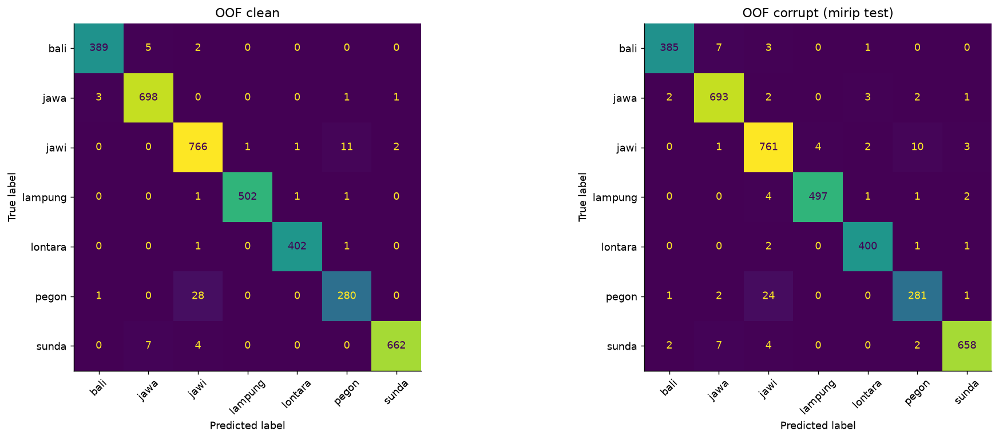

,bucket,n,f1_clean,f1_corrupt
0,<2,926,0.9346,0.9092
1,2-10,1508,0.9643,0.9609
2,>10,1337,0.9992,0.9965


In [29]:
done_folds = [k for k in FOLDS if (OUT / f'fold{k}_test_logits.npy').exists()]
assert done_folds, 'belum ada fold selesai'
idx = np.concatenate([np.load(OUT / f'fold{k}_val_idx.npy') for k in done_folds])
oof_c = np.concatenate([np.load(OUT / f'fold{k}_oof_clean_logits.npy') for k in done_folds])
oof_x = np.concatenate([np.load(OUT / f'fold{k}_oof_corrupt_logits.npy') for k in done_folds])
y_oof = y_all[idx]

fold_rows = []
for k in done_folds:
    h = pd.read_csv(OUT / f'fold{k}_history.csv'); b = h.loc[h.f1_corrupt.idxmax()]
    fold_rows.append(dict(fold=k, best_epoch=int(b.epoch), f1_clean=b.f1_clean, f1_corrupt=b.f1_corrupt))
fold_df = pd.DataFrame(fold_rows); display(fold_df); fold_df.to_csv(OUT / 'fold_metrics.csv', index=False)

summary = dict(run=RUN_NAME, folds=done_folds, oof_f1_clean=macro_f1(y_oof, oof_c), oof_f1_corrupt=macro_f1(y_oof, oof_x),
               fold_f1_corrupt_mean=fold_df.f1_corrupt.mean(), fold_f1_corrupt_std=fold_df.f1_corrupt.std())
v1_summary = ROOT / 'results/v1/summary.json'
if v1_summary.exists():
    summary['v1_holdout_f1_random_split'] = json.loads(v1_summary.read_text())['holdout_macro_f1']
    summary['v1_public_lb'] = 0.86289
print(json.dumps(summary, indent=2))

rep = classification_report(y_oof, oof_x.argmax(1), target_names=LABELS, output_dict=True, zero_division=0)
display(pd.DataFrame(rep).T.round(4)); pd.DataFrame(rep).T.to_csv(OUT / 'oof_corrupt_per_class.csv')
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, lg, t in [(ax[0], oof_c, 'OOF clean'), (ax[1], oof_x, 'OOF corrupt (mirip test)')]:
    ConfusionMatrixDisplay(confusion_matrix(y_oof, lg.argmax(1)), display_labels=LABELS).plot(ax=a, xticks_rotation=45, colorbar=False); a.set_title(t)
plt.tight_layout(); plt.savefig(OUT / 'oof_confusion.png', dpi=90); plt.show(); plt.close(fig)

# bucket seperti v1: aspect ratio gambar asli + line / non-line
ratio = np.array([a.shape[1] / a.shape[0] for a in train_raw])[idx]
bucket = np.where(ratio < 2, '<2', np.where(ratio <= 10, '2-10', '>10'))
rows = []
for b in ['<2', '2-10', '>10']:
    m = bucket == b
    rows.append(dict(bucket=b, n=int(m.sum()), f1_clean=macro_f1(y_oof[m], oof_c[m]), f1_corrupt=macro_f1(y_oof[m], oof_x[m])))
display(pd.DataFrame(rows).round(4)); pd.DataFrame(rows).to_csv(OUT / 'oof_ratio_buckets.csv', index=False)
pd.DataFrame({'image_id': train.image_id.values[idx], 'label': train.label.values[idx], 'fold': train.fold.values[idx],
              'pred_clean': [LABELS[i] for i in oof_c.argmax(1)], 'pred_corrupt': [LABELS[i] for i in oof_x.argmax(1)]}
             ).to_csv(OUT / 'oof_predictions.csv', index=False)

Submission v2: rata-rata probabilitas lima fold (tile dirata-ratakan per gambar), lalu twins memakai label train. Logit test v2 inilah yang dipakai hybrid untuk non-page.

In [30]:
probs = np.mean([torch.softmax(torch.from_numpy(np.load(OUT / f'fold{k}_test_logits.npy')), 1).numpy() for k in done_folds], axis=0)
assert probs.shape == (len(test), len(LABELS)) and np.allclose(probs.sum(1), 1)
pred = np.array([LABELS[i] for i in probs.argmax(1)], dtype=object)

if USE_TWINS and len(twins):
    tw = test.image_id.map(twins.set_index('image_id').train_label)
    m = tw.notna().values
    print(f'twins: {m.sum()} gambar, {int((pred[m] != tw[m].values).sum())} prediksi berubah ke label train')
    pred[m] = tw[m].values

submission = pd.DataFrame({'image_id': test.image_id, 'label': pred})
submission = sample_sub[['image_id']].merge(submission, on='image_id', how='left')
assert len(submission) == len(sample_sub) and submission.label.notna().all() and set(submission.label) <= set(LABELS)
submission.to_csv(OUT / 'submission.csv', index=False)
pd.DataFrame(probs, columns=LABELS).assign(image_id=test.image_id.values).to_csv(OUT / 'test_probabilities.csv', index=False)

dist = pd.DataFrame({'test_pred_%': submission.label.value_counts(normalize=True) * 100,
                     'train_%': train.label.value_counts(normalize=True) * 100}).round(1)
display(dist)
v1_sub = ROOT / 'results/v1/submission.csv'
if v1_sub.exists():
    s1 = sample_sub[['image_id']].merge(pd.read_csv(v1_sub), on='image_id')
    print(f'beda dengan submission v1: {(s1.label.values != submission.label.values).mean():.1%} baris')

config = {k: v for k, v in dict(globals()).items() if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple))}
config.update(torch=torch.__version__, timm=timm.__version__, python=platform.python_version(), gpu=torch.cuda.get_device_name())
(OUT / 'config.json').write_text(json.dumps(config, indent=2, default=str))
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2, default=float))
print('SELESAI ->', OUT / 'submission.csv')

twins: 17 gambar, 0 prediksi berubah ke label train


,test_pred_%,train_%
label,,
bali,8.8,10.5
jawa,18.9,18.6
jawi,13.9,20.7
lampung,19.0,13.4
lontara,9.3,10.7
pegon,16.7,8.2
sunda,13.4,17.8


SELESAI -> /workspace/infest/results/v2/main/submission.csv


#### Result dan Decision

| Metrik | Run ini | Run LB |
|---|---:|---:|
| OOF F1 bersih | 0,9787 | 0,9819 |
| OOF F1 terkorupsi | 0,9726 | 0,9735 |
| OOF testlike | 0,9761 | 0,9771 |
| Page benar | 160/199 | 161/199 |

> Skor sebanding dengan run LB; selisih 0,001 pada testlike berasal dari nondeterminisme GPU dan versi torch, bukan kode. Submission v2 notebook ini sama dengan submission LB 0,91514 pada 1.203 dari 1.220 baris.

> Epoch terbaik per fold bervariasi (2 sampai 10) dan fold 4 berhenti lebih awal di epoch 6, tanda kurva validasi datar setelah beberapa epoch. Page adalah titik lemah v2: hanya 0,804 benar, jauh di bawah baris 0,993.

**Decision: KEEP** untuk non-page. Page ditangani Experiment 2.

---

# Experiment 2: v5, View Resolusi Tinggi untuk Page <a name="9"></a>

---

### Question

> Apakah page dibaca lebih baik pada 640x640 dibanding letterbox 160x640 v2?

### Hypothesis

> Probe DINOv3 beku pada 199 page train: akurasi 0,60 (view v2) ke 0,69 (448) ke 0,73 (640). View 640 seharusnya menaikkan akurasi page OOF tanpa mengubah non-page.

### Change from v2

| | v2 | v5 |
|---|---|---|
| baris / block / glyph | corrupt, preprocess, 160x640 | sama persis |
| page | preprocess, letterbox 160x640 | gray mentah, letterbox 640x640, augmentasi foto ringan |
| batch | 16 kanvas 160x640 | micro-batch homogen: 16 non-page atau 4 page; sekitar 20% page |
| validasi page | view terkorupsi | view bersih |

Kode di bawah disalin dari `notebooks/v5.ipynb`. Cell berikut membebaskan cache v2 sebelum cache v5 dibuat.

In [31]:
for _name in ['train_raw', 'train_pp', 'test_pp', 'clean_tiles', 'cor_tiles', 'test_tiles']:
    globals().pop(_name, None)
gc.collect()

153

## [9.1] Konfigurasi v5

In [32]:
def find_root():
    for c in [Path.cwd(), Path.cwd().parent, Path('/workspace/infest-26'), Path('/workspace')]:
        if (c / 'data/train.csv').exists():
            return c
    raise FileNotFoundError('data/train.csv tidak ditemukan - set ROOT manual')


ROOT = find_root()
DATA = ROOT / 'data'

SMOKE_TEST = False            # True: fold 0, 1 epoch
RUN_NAME = 'main'             # output + resume key: results/v5/<RUN_NAME>
SEED = 42
MODEL_NAME = 'vit_large_patch16_dinov3.lvd1689m'
H, W = 160, 640               # eda/07: tinggi tetap 160 -> tinta ~10 patch
EPOCHS, WARMUP_EPOCHS, PATIENCE = 12, 1, 4
MICRO_BATCH, ACCUM = 16, 2    # efektif 32; 5090 32GB muat tanpa grad checkpointing
EVAL_BATCH = 64
GRAD_CKPT = False             # True jika OOM
BASE_LR, HEAD_LR = 4e-5, 3e-4 # BASE_LR = blok teratas; blok bawah dikali LAYER_DECAY^depth
LAYER_DECAY, WEIGHT_DECAY = 0.85, 0.05
LABEL_SMOOTHING = 0.1
NONLINE_BOOST = 1.5           # prepro/03: non-line 41% test vs 21% train
FOLDS = [0, 1, 2, 3, 4]
NUM_WORKERS = max(4, min(28, (os.cpu_count() or 8) - 2))
PAGE_S = 640                  # eda/22: page acc .60 (v2 view) -> .69 (448) -> .73 (640)
PAGE_MB = 4                   # 4 x 1600 token = memori setara 16 x 400 token (line)
PAGE_P = 0.2                  # porsi micro-batch page per epoch (page 5.3% train, 24.6% test)
PAGE_EVAL_BATCH = 16
RAW_MAX_SIDE = 1600           # poster 5000px diperkecil sekali saat cache (canvas tetap 160 tinggi)
USE_TWINS = True              # 17 test near-copy train -> pakai label train
SAVE_WEIGHTS = False          # True: simpan state bf16 per fold (~600MB/fold)
LABELS = ['bali', 'jawa', 'jawi', 'lampung', 'lontara', 'pegon', 'sunda']
LABEL_TO_ID = {l: i for i, l in enumerate(LABELS)}
if SMOKE_TEST:
    EPOCHS, FOLDS, RUN_NAME = 1, [0], 'smoke'

assert torch.cuda.is_available(), 'Butuh GPU CUDA'
DEVICE = torch.device('cuda')
cap = torch.cuda.get_device_capability()
assert cap[0] < 12 or any(a.startswith('sm_12') for a in torch.cuda.get_arch_list()), \
    'torch ini tidak support RTX 5090 (sm_120): pip install -U torch torchvision --index-url https://download.pytorch.org/whl/cu128'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


seed_all(SEED)
OUT = ROOT / 'results' / 'v5' / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
print(dict(root=str(ROOT), torch=torch.__version__, timm=timm.__version__, gpu=torch.cuda.get_device_name(),
           capability=cap, cpus=os.cpu_count(), workers=NUM_WORKERS, out=str(OUT)))

{'root': '/workspace/infest', 'torch': '2.8.0+cu128', 'timm': '1.0.27', 'gpu': 'NVIDIA GeForce RTX 5090', 'capability': (12, 0), 'cpus': 16, 'workers': 14, 'out': '/workspace/infest/results/v5/main'}


## [9.2] Pipeline v2 ditambah view page

Fungsi v2 identik; tambahan `is_page`, `letterbox`, `page_eval`, dan `page_train`.

In [33]:
"""Preprocessing + augmentation for INFEST aksara classification. Import this from the training notebook.

Order matters:   raw RGB --(train only) corrupt()--> preprocess() --> to_canvas()
corrupt() BEFORE preprocess() because the test corruptions were applied to raw images; the network must
see train images that went through exactly the same normalisation the corrupted test images go through.

Every number below comes from eda/outputs (see eda/README.md):
  rotation +-15 deg          07: test |skew| p95=10, p99=13; 30% of test lines >=3 deg (train 4%)
  tint p=.45                 03: bg_sat>12 in 44% test vs 3% train
  blur/pixelate p=.55        03: sharp<0.6 in 69% test vs 12% train
  occluder p=.12, dashes .15 03 flat_gray 6.6% test (detector under-counts, seen in 02 zoom)
  black bar p=.07            03: black border 7.3% test vs 1.2% train
  jpeg p=.3                  01: JPEG 21% test vs 4.6% train
  canvas H=160 fixed height  07: letterbox 160x640 leaves bali/lontara at ~2 patches of ink
"""



# ----------------------------------------------------------------------------- load
def load_rgb(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        if im.mode in ("RGBA", "LA", "P", "PA"):
            im = im.convert("RGBA")
            im = Image.alpha_composite(Image.new("RGBA", im.size, "white"), im)
        return im.convert("RGB")


# ----------------------------------------------------------------------------- deterministic (train + test)
def _otsu(g):
    hist = np.bincount(g.ravel(), minlength=256).astype(float)
    p = hist / hist.sum(); w = np.cumsum(p); mu = np.cumsum(p * np.arange(256))
    return int(np.argmax((mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12)))


def remove_black_fill(g, dark=40, min_contact=0.3, min_solidity=0.9, max_holes=0.03):
    """Solid black regions glued to the border (shift / rotate fill, black bars) -> white.
    A border-touching pure-black component is fill when it has no holes (a real dark background has
    light text inside it) AND either (a) runs along >=min_contact of a side or (b) is near-convex
    (rotation corner triangle). Glyph-sized images (both sides <64px) only lose full-side bars.
    Only the thick core (survives 2px erosion) is removed, so thin strokes glued to the fill stay."""
    blk = g < dark
    if not blk.any():
        return g
    lab, n = ndi.label(blk)
    h, w = g.shape
    border = np.zeros_like(blk); border[0] = border[-1] = border[:, 0] = border[:, -1] = True
    tiny = max(h, w) < 64  # glyph-sized crops (e.g. a 20x20 bold numeral): only full-side bars count
    contact = 0.9 if tiny else min_contact
    objs = ndi.find_objects(lab)
    kill = set()
    for i in set(np.unique(lab[border & blk]).tolist()) - {0}:
        sl = objs[i - 1]
        comp = lab[sl] == i
        area = comp.sum()
        filled = ndi.binary_fill_holes(comp).sum()
        if (filled - area) / filled > max_holes or np.median(g[sl][comp]) > 15:
            continue
        run = max((lab[0] == i).sum() / w, (lab[-1] == i).sum() / w, (lab[:, 0] == i).sum() / h, (lab[:, -1] == i).sum() / h)
        if run >= contact:
            kill.add(i); continue
        if tiny or area < 0.005 * g.size:
            continue
        ys, xs = np.nonzero(comp)
        try:
            from scipy.spatial import ConvexHull
            hull = ConvexHull(np.c_[np.r_[ys, ys + 1, ys, ys + 1], np.r_[xs, xs, xs + 1, xs + 1]]).volume
        except Exception:
            continue
        if area / hull >= min_solidity:
            kill.add(i)
    if not kill:
        return g
    mask = np.isin(lab, list(kill))
    mask &= ndi.binary_dilation(ndi.binary_erosion(mask, iterations=2, border_value=1), iterations=3)
    out = g.copy()
    out[mask] = 255
    return out


def preprocess(rgb):
    """RGB PIL -> L PIL: gray, black fill removed, dark-ink-on-white, contrast normalised, cropped to ink.
    Fill removal runs BEFORE the polarity test: black rotation corners on a thin line can cover >50% of
    the frame and would otherwise flip the whole image to white-on-black (seen in debug_black_rotation.png)."""
    g = remove_black_fill(np.asarray(rgb.convert("L")))
    t = _otsu(g)
    if (g > t).mean() < 0.5:  # background is the majority class; if it is the dark side, invert
        g = 255 - g
    t = _otsu(g)
    ink, bg = g[g <= t], g[g > t]
    if ink.size and bg.size:
        lo, hi = np.percentile(ink, 10), np.median(bg)
        if hi - lo >= 20:  # skip blank / single-tone images
            g = np.clip((g.astype(np.float32) - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    return Image.fromarray(crop_to_ink(g))


def crop_to_ink(g, thr=128, trim=0.005, margin=0.08):
    ink = g < thr
    if ink.sum() < 20:
        return g
    def span(profile):
        c = np.cumsum(profile) / profile.sum()
        return int(np.searchsorted(c, trim)), int(np.searchsorted(c, 1 - trim))
    y0, y1 = span(ink.sum(1)); x0, x1 = span(ink.sum(0))
    if ink[y0:y1 + 1, x0:x1 + 1].mean() > 0.6:  # crop would be one solid blob (a black dash on a sparse page) -> keep all
        return g
    m = int(round(margin * max(y1 - y0, 8)))
    return g[max(0, y0 - m):y1 + m + 1, max(0, x0 - m):x1 + m + 1]


def to_canvas(img, H=160, W=640, train=False, rng=random):
    """Line-like crops (w/h>=2): resize to fixed height H, then random window (train) or tiles (eval).
    Others (posters, pages, square patches): letterbox. Returns list of HxW L images (len 1 when train)."""
    w, h = img.size
    if w / h >= 2:
        nw = max(1, round(w * H / h))
        img = img.resize((nw, H), Image.Resampling.BICUBIC if nw > w else Image.Resampling.LANCZOS)
        if nw <= W:
            c = Image.new("L", (W, H), 255); c.paste(img, ((W - nw) // 2, 0)); return [c]
        if train:
            x = rng.randint(0, nw - W); return [img.crop((x, 0, x + W, H))]
        n = math.ceil((nw - W) / (W // 2)) + 1
        xs = np.linspace(0, nw - W, n).round().astype(int)
        return [img.crop((x, 0, x + W, H)) for x in xs]
    s = min(H / h, W / w)
    img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.Resampling.BICUBIC if s > 1 else Image.Resampling.LANCZOS)
    c = Image.new("L", (W, H), 255); c.paste(img, ((W - img.width) // 2, (H - img.height) // 2)); return [c]


# ----------------------------------------------------------------------------- train-only test-like corruption
PARCHMENT = [(236, 224, 196), (222, 205, 170), (245, 238, 214), (210, 196, 160), (196, 186, 160), (250, 246, 230), (170, 170, 170), (230, 230, 230)]
INKS = [(20, 20, 20), (90, 20, 30), (30, 70, 40), (40, 40, 90), (70, 50, 30), (60, 30, 80)]


def rotate(img, angle, fill="edge"):
    """RandomRotation that mimics the test set: frame size kept, corners filled by edge-replicate / white / black."""
    if fill == "edge":
        a = np.asarray(img); pad = max(a.shape[:2]) // 2
        big = Image.fromarray(np.pad(a, ((pad, pad), (pad, pad), (0, 0)), mode="edge"))
        big = big.rotate(angle, resample=Image.Resampling.BICUBIC)
        return big.crop((pad, pad, pad + img.width, pad + img.height))
    color = (255, 255, 255) if fill == "white" else (0, 0, 0)
    return img.rotate(angle, resample=Image.Resampling.BICUBIC, fillcolor=color)


def _ink_mask(img):
    g = np.asarray(img.convert("L")); return g < min(_otsu(g), 128)


def ink_retained(img, angle):
    """Share of the ORIGINAL ink still inside the frame after rotation (fill can't fake it)."""
    m = Image.fromarray(_ink_mask(img).astype(np.uint8) * 255)
    return (np.asarray(m.rotate(angle, resample=Image.Resampling.NEAREST, fillcolor=0)) > 0).sum() / max((np.asarray(m) > 0).sum(), 1)


def corrupt(img, rng=random):
    """RGB PIL -> RGB PIL with test-like corruptions. Rotation angle is re-drawn while <60% of the ink stays in frame."""
    w, h = img.size
    if rng.random() < 0.5:
        for _ in range(4):
            angle = rng.uniform(-15, 15)
            if ink_retained(img, angle) >= 0.6:
                img = rotate(img, angle, rng.choice(["edge"] * 5 + ["white"] * 2 + ["black"])); break
    if rng.random() < 0.25 and w > 60:  # partial crop along the line
        cw, ch = int(w * rng.uniform(0.6, 1.0)), int(h * rng.uniform(0.85, 1.0))
        x, y = rng.randint(0, w - cw), rng.randint(0, h - ch)
        img = img.crop((x, y, x + cw, y + ch)); w, h = img.size
    if rng.random() < 0.45:  # tint: re-colour ink and paper
        g = np.asarray(img.convert("L"), dtype=np.float32)[..., None] / 255
        bg = np.array(rng.choice(PARCHMENT), dtype=np.float32) * rng.uniform(0.85, 1.05)
        ink = np.array(rng.choice(INKS), dtype=np.float32) + rng.uniform(0, 60)
        img = Image.fromarray(np.clip(ink * (1 - g) + bg * g, 0, 255).astype(np.uint8))
    if rng.random() < 0.45:
        if rng.random() < 0.5:
            img = img.filter(ImageFilter.GaussianBlur(rng.uniform(0.3, 1.2) * max(h, 32) / 64))
        else:
            f = rng.uniform(0.35, 0.8)
            small = img.resize((max(4, int(w * f)), max(4, int(h * f))), Image.Resampling.BILINEAR)
            img = small.resize((w, h), rng.choice([Image.Resampling.NEAREST, Image.Resampling.BILINEAR, Image.Resampling.BICUBIC]))
    if rng.random() < 0.08:  # semi-transparent gray polygons
        over = Image.new("RGBA", img.size, (0, 0, 0, 0)); d = ImageDraw.Draw(over)
        for _ in range(rng.randint(1, 3)):
            v = rng.randint(60, 150)
            d.polygon([(rng.uniform(-.1, 1.1) * w, rng.uniform(-.1, 1.1) * h) for _ in range(3)], fill=(v, v, v, rng.randint(120, 230)))
        img = Image.alpha_composite(img.convert("RGBA"), over).convert("RGB")
    if rng.random() < 0.15:  # small black dashes / cutout
        d = ImageDraw.Draw(img)
        for _ in range(rng.randint(1, 4)):
            rw, rh = rng.uniform(.03, .1) * w, rng.uniform(.03, .1) * h + 1
            x, y = rng.uniform(0, w - rw), rng.uniform(0, h - rh)
            d.rectangle([x, y, x + rw, y + rh], fill=(0, 0, 0))
    if rng.random() < 0.07:  # black bar from a vertical shift
        a = np.asarray(img).copy(); k = int(h * rng.uniform(0.05, 0.25)) + 1
        if rng.random() < 0.5:
            a[:-k] = a[k:]; a[-k:] = 0
        else:
            a[k:] = a[:-k]; a[:k] = 0
        img = Image.fromarray(a)
    if rng.random() < 0.15:
        a = np.asarray(img, dtype=np.float32) + np.random.default_rng(rng.randint(0, 2**31)).normal(0, rng.uniform(5, 25), (h, w, 1))
        img = Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    if rng.random() < 0.3:
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=rng.randint(20, 75)); buf.seek(0)
        img = Image.open(buf).convert("RGB")
    return img


def train_view(path, rng=random, H=160, W=640):
    return to_canvas(preprocess(corrupt(load_rgb(path), rng)), H, W, train=True, rng=rng)[0]


def eval_views(path, H=160, W=640):
    return to_canvas(preprocess(load_rgb(path)), H, W, train=False)

# ---- self-check (same asserts as prepro/pipeline.py)
img = Image.new("RGB", (400, 60), "white"); ImageDraw.Draw(img).text((10, 20), "abc def ghi jkl", fill="black")
p = preprocess(img)
assert p.mode == "L" and p.width < 400 and np.asarray(p).min() == 0
inv = preprocess(ImageOps.invert(img))  # white-on-black must come out black-on-white
assert np.asarray(inv).mean() > 128
barred = np.asarray(img).copy(); barred[-15:] = 0
g = remove_black_fill(np.asarray(Image.fromarray(barred).convert("L")))
assert (g[-15:] == 255).all() and (g < 128).sum() > 0, "bar removed, text kept"
page = np.full((800, 600), 255, np.uint8); page[::40, ::40] = 180; page[400:410, 300:360] = 0
assert crop_to_ink(page).shape == page.shape, "sparse page + black dash must not collapse to the dash"
views = to_canvas(Image.new("L", (3000, 80), 255), train=False)
assert all(v.size == (640, 160) for v in views) and len(views) > 1
r = random.Random(0)
for _ in range(50):
    c = corrupt(img, r); assert c.mode == "RGB"
print("pipeline self-check OK")


# ----------------------------------------------------------------------------- round 4: page view (prepro/page_view.py)
PAGE_MIN_H = 250


def is_page(size):
    """size = (w, h) of the ORIGINAL file (before any cache thumbnail)."""
    return size[1] >= PAGE_MIN_H


def letterbox(img, S):
    """grey L image -> SxS, aspect kept, white padding."""
    s = S / max(img.size)
    img = img.resize((max(1, round(img.width * s)), max(1, round(img.height * s))),
                     Image.Resampling.LANCZOS if s < 1 else Image.Resampling.BICUBIC)
    c = Image.new("L", (S, S), 255); c.paste(img, ((S - img.width) // 2, (S - img.height) // 2)); return c


def page_eval(rgb, S):
    return letterbox(rgb.convert("L"), S)


def page_train(rgb, S, rng=random):
    """mild photo-like augmentation (eda/23: test pages are clean web photos, not synthetically corrupted).
    Strengths calibrated in prepro/08 so that train-aug canvases stay indistinguishable from test pages
    (first try with blur p=.5 / rotate-expand p=.4 / gamma .75-1.33 opened a gap: domain AUC .45 -> .67)."""
    w, h = rgb.size
    if rng.random() < 0.6:  # re-framing: keep 85-100% of each side (layout / genre cues live at the borders too)
        cw, ch = int(w * rng.uniform(.85, 1)), int(h * rng.uniform(.85, 1))
        x, y = rng.randint(0, w - cw), rng.randint(0, h - ch)
        rgb = rgb.crop((x, y, x + cw, y + ch))
    g = rgb.convert("L")
    if rng.random() < 0.25:  # camera tilt, same canvas size; corners get the border median (no black wedge)
        a = np.asarray(g)
        fill = int(np.median(np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])))
        g = g.rotate(rng.uniform(-5, 5), resample=Image.Resampling.BICUBIC, expand=False, fillcolor=fill)
    if rng.random() < 0.4:  # exposure: gamma + contrast (grey-level ColorJitter)
        a = np.asarray(g, dtype=np.float32) / 255
        a = a ** rng.uniform(.85, 1.18)
        m = a.mean(); a = np.clip((a - m) * rng.uniform(.85, 1.15) + m, 0, 1)
        g = Image.fromarray((a * 255).astype(np.uint8))
    if rng.random() < 0.15:  # low-res web copy
        f = rng.uniform(.5, .9)
        small = g.resize((max(8, int(g.width * f)), max(8, int(g.height * f))), Image.Resampling.BILINEAR)
        g = small.resize(g.size, Image.Resampling.BICUBIC)
    if rng.random() < 0.3:
        b = io.BytesIO(); g.save(b, "JPEG", quality=rng.randint(50, 95)); g = Image.open(io.BytesIO(b.getvalue())).convert("L")
    return letterbox(g, S)

pipeline self-check OK


## [9.3] Data, cache, dan kanvas page

In [34]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
sample_sub = pd.read_csv(DATA / 'sample_submission.csv')
assert set(train.label) == set(LABELS) and train.image_id.is_unique and test.image_id.is_unique
assert not set(train.image_id) & set(test.image_id)

folds_path = next((p for p in [DATA / 'folds.csv', ROOT / 'prepro/outputs/folds.csv'] if p.exists()), None)
assert folds_path is not None, 'folds.csv tidak ada: upload data/folds.csv (hasil prepro/05_make_folds.py)'
folds = pd.read_csv(folds_path)
assert set(folds.image_id) == set(train.image_id), 'folds.csv tidak cocok dengan train.csv'
train = train.merge(folds[['image_id', 'dup_group', 'fold', 'weight']], on='image_id', how='left')
assert (train.groupby('dup_group').fold.nunique() == 1).all(), 'dup_group bocor antar fold'

twins_path = next((p for p in [DATA / 'test_train_twins.csv', ROOT / 'prepro/outputs/test_train_twins.csv'] if p.exists()), None)
twins = pd.read_csv(twins_path) if twins_path else pd.DataFrame(columns=['image_id', 'train_label', 'n_labels'])
twins = twins[twins.image_id.isin(test.image_id) & (twins.n_labels == 1)]

train['path'] = [str(DATA / 'images/train' / i) for i in train.image_id]
test['path'] = [str(DATA / 'images/test' / i) for i in test.image_id]
y_all = train.label.map(LABEL_TO_ID).values
print('folds:', train.fold.value_counts().sort_index().to_dict(), '| twins:', len(twins))
display(pd.crosstab(train.label, train.fold))

folds: {0: 754, 1: 754, 2: 755, 3: 754, 4: 754} | twins: 17


fold,0,1,2,3,4
label,,,,,
bali,79,80,79,79,79
jawa,140,141,141,141,140
jawi,156,157,156,156,156
lampung,101,101,101,101,101
lontara,81,80,81,81,81
pegon,62,61,62,62,62
sunda,135,134,135,134,135


Cache yang sama dengan v2, ditambah kanvas page 640x640 untuk train dan test. Page test dibaca ulang dari berkas mentah karena cache test hanya menyimpan hasil preprocess.

In [35]:
def load_cached(path):
    img = load_rgb(path)
    if max(img.size) > RAW_MAX_SIDE:
        img.thumbnail((RAW_MAX_SIDE, RAW_MAX_SIDE), Image.Resampling.LANCZOS)
    return np.asarray(img), np.asarray(preprocess(img))


def load_raw_small(path):  # raw test page (cache test hanya menyimpan hasil preprocess)
    img = load_rgb(path)
    if max(img.size) > RAW_MAX_SIDE:
        img.thumbnail((RAW_MAX_SIDE, RAW_MAX_SIDE), Image.Resampling.LANCZOS)
    return np.asarray(img)


def corrupted_val_pp(args):
    # val terkorupsi FIXED (seed per gambar) -> skor antar epoch/fold sebanding
    arr, j = args
    return np.asarray(preprocess(corrupt(Image.fromarray(arr), random.Random(f'val-{SEED}-{j}'))))


t0 = time.time()
with Pool(NUM_WORKERS) as pool:
    tr_cache = pool.map(load_cached, list(train.path), chunksize=16)
    te_cache = pool.map(load_cached, list(test.path), chunksize=16)
    train_raw = [a for a, _ in tr_cache]
    train_pp = [p for _, p in tr_cache]
    test_pp = [p for _, p in te_cache]
    del tr_cache, te_cache
    train_pp_cor = pool.map(corrupted_val_pp, [(a, j) for j, a in enumerate(train_raw)], chunksize=16)
print(f'cache {time.time() - t0:.0f}s')

def orig_size(p):
    with Image.open(p) as im:
        return im.size


train_is_page = np.array([is_page(orig_size(p)) for p in train.path])
test_is_page = np.array([is_page(orig_size(p)) for p in test.path])
print(f'page share: train {train_is_page.mean():.1%} ({train_is_page.sum()}) | test {test_is_page.mean():.1%} ({test_is_page.sum()})')
nonline = np.array([p.shape[1] / p.shape[0] < 2 for p in train_pp])
test_nonline = np.array([p.shape[1] / p.shape[0] < 2 for p in test_pp])
print(f'non-line share: train {nonline.mean():.1%} | test {test_nonline.mean():.1%}')


def build_tiles(pps, is_pg):
    # v2 tiles for non-pages only; pages get page canvases below
    tiles, owner = [], []
    for k, pp in enumerate(pps):
        if is_pg[k]:
            continue
        for t in to_canvas(Image.fromarray(pp), H, W, train=False):
            tiles.append(np.asarray(t, dtype=np.uint8)); owner.append(k)
    return np.stack(tiles), np.array(owner)


clean_tiles, clean_owner = build_tiles(train_pp, train_is_page)
cor_tiles, cor_owner = build_tiles(train_pp_cor, train_is_page)
test_tiles, test_owner = build_tiles(test_pp, test_is_page)
del train_pp_cor
print('tiles train/cor/test:', len(clean_tiles), len(cor_tiles), len(test_tiles))


def page_eval_arr(a):
    return np.asarray(page_eval(Image.fromarray(a), PAGE_S), dtype=np.uint8)


with Pool(NUM_WORKERS) as pool:
    train_page_owner = np.where(train_is_page)[0]
    train_page = np.stack(pool.map(page_eval_arr, [train_raw[j] for j in train_page_owner], chunksize=4))
    test_page_owner = np.where(test_is_page)[0]
    test_page = np.stack(pool.map(page_eval_arr, pool.map(load_raw_small, [test.path[j] for j in test_page_owner], chunksize=4), chunksize=4))
print('page canvases train/test:', train_page.shape, test_page.shape)

cache 12s


page share: train 5.3% (199) | test 24.6% (300)
non-line share: train 22.7% | test 40.6%


tiles train/cor/test: 14481 13655 3121


page canvases train/test: (199, 640, 640) (300, 640, 640)


## [9.4] Dataset, sampler homogen, dan pemeriksaan visual

In [36]:
MEAN_G = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD_G = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def gpu_norm(x):  # uint8 (B,1,H,W) -> normalised float (B,3,H,W)
    return (x.float().div_(255).expand(-1, 3, -1, -1) - MEAN_G) / STD_G


class TrainDS(Dataset):
    # non-page: corrupt -> preprocess -> random window (v2). page: page_train. Seed = (SEED, epoch, image) -> reproducible at any num_workers
    def __init__(self, idx, seed=SEED):
        self.idx, self.epoch, self.seed = np.asarray(idx), 0, seed

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = int(self.idx[i])
        rng = random.Random(f'{self.seed}-{self.epoch}-{j}')
        if train_is_page[j]:  # round 4: page -> square grey view
            v = page_train(Image.fromarray(train_raw[j]), PAGE_S, rng)
            return torch.from_numpy(np.asarray(v, dtype=np.uint8).copy()).unsqueeze(0), int(y_all[j])
        v = to_canvas(preprocess(corrupt(Image.fromarray(train_raw[j]), rng)), H, W, train=True, rng=rng)[0]
        return torch.from_numpy(np.asarray(v, dtype=np.uint8).copy()).unsqueeze(0), int(y_all[j])


def subset_tiles(tiles, owner, idx):
    pos = {int(j): k for k, j in enumerate(idx)}
    m = np.isin(owner, idx)
    return tiles[m], np.array([pos[int(o)] for o in owner[m]])


@torch.inference_mode()
def predict_logits(model, groups, n):
    # groups: [(canvases, owner), ...] - v2 tiles (160x640) and page canvases (PAGE_S^2); mean logits per image
    model.eval()
    out = torch.zeros(n, len(LABELS), dtype=torch.float64)
    cnt = torch.zeros(n, 1, dtype=torch.float64)
    for tiles, owner in groups:
        bs = EVAL_BATCH if tiles.shape[1] == H else PAGE_EVAL_BATCH
        for s in range(0, len(tiles), bs):
            x = gpu_norm(torch.from_numpy(tiles[s:s + bs]).to(DEVICE).unsqueeze(1))
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lg = model(x).float().cpu().double()
            o = torch.from_numpy(owner[s:s + bs]).long()
            out.index_add_(0, o, lg)
            cnt.index_add_(0, o, torch.ones(len(o), 1, dtype=torch.float64))
    assert (cnt > 0).all(), 'ada gambar tanpa canvas'
    return (out / cnt).numpy()


class MixedBatchSampler:
    # Micro-batch homogen (satu ukuran tensor per batch): non-page MICRO_BATCH x 160x640 dengan bobot sampler v2,
    # page PAGE_MB x PAGE_S^2 dengan bobot dup-group. Jumlah batch non-page per epoch = v2; page ditambah PAGE_P.
    def __init__(self, idx, seed):
        idx = np.asarray(idx); pos = np.arange(len(idx)); pg = train_is_page[idx]
        self.np_pos, self.pg_pos = pos[~pg], pos[pg]
        w = train.weight.values[idx]
        self.np_w = w[~pg] * np.where(nonline[idx][~pg], NONLINE_BOOST, 1.0); self.pg_w = w[pg]
        self.n_np = len(self.np_pos) // MICRO_BATCH
        self.n_pg = int(round(self.n_np * PAGE_P / (1 - PAGE_P))) if len(self.pg_pos) else 0
        self.seed, self.epoch = seed, 0

    def __len__(self):
        return self.n_np + self.n_pg

    def __iter__(self):
        g = np.random.default_rng(self.seed * 1000 + self.epoch)
        a = g.choice(self.np_pos, size=(self.n_np, MICRO_BATCH), p=self.np_w / self.np_w.sum())
        b = g.choice(self.pg_pos, size=(self.n_pg, PAGE_MB), p=self.pg_w / self.pg_w.sum()) if self.n_pg else np.zeros((0, PAGE_MB), int)
        batches = [r.tolist() for r in a] + [r.tolist() for r in b]
        for k in g.permutation(len(batches)):
            yield batches[k]

Pemeriksaan visual sebelum training: non-page dalam empat tahap, page per kelas (mentah, view evaluasi, dua view training), contoh page test, dan ringkasan porsi tinta tiap view.

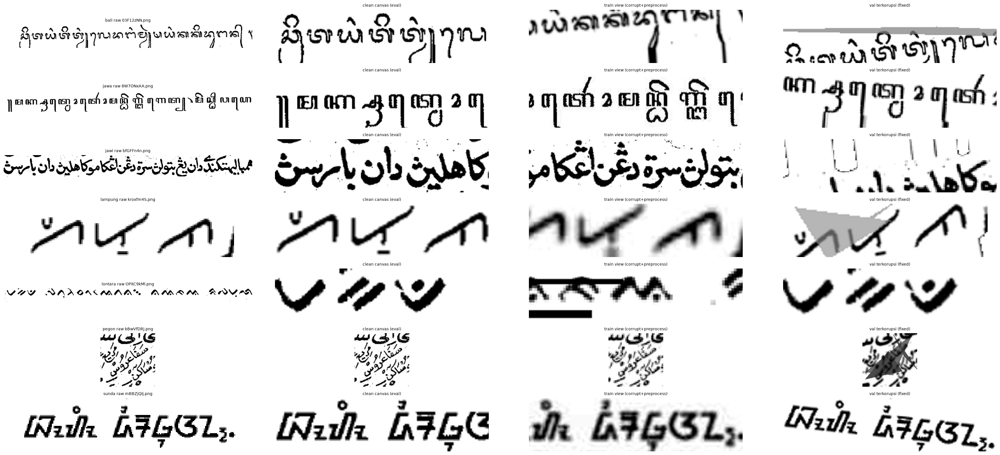

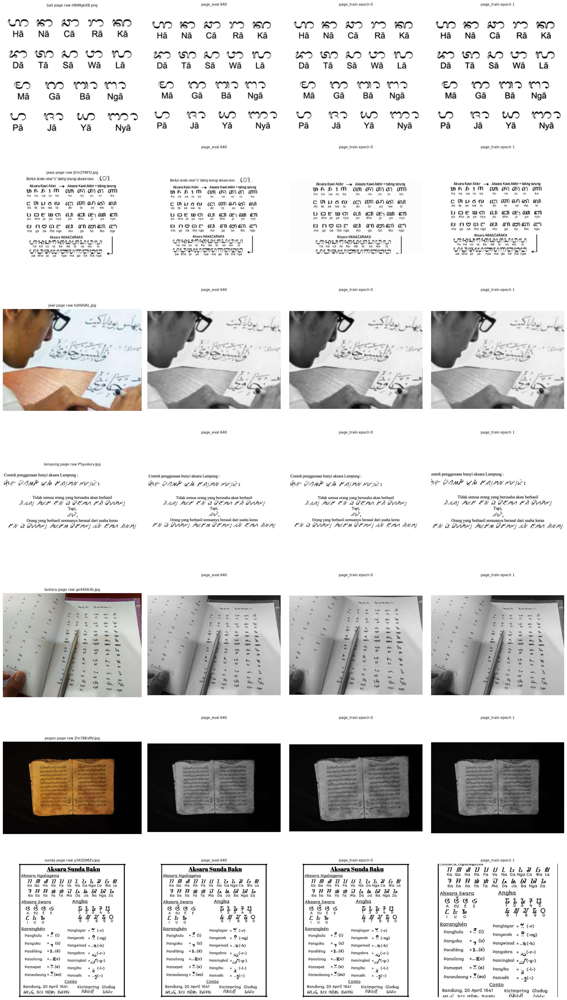

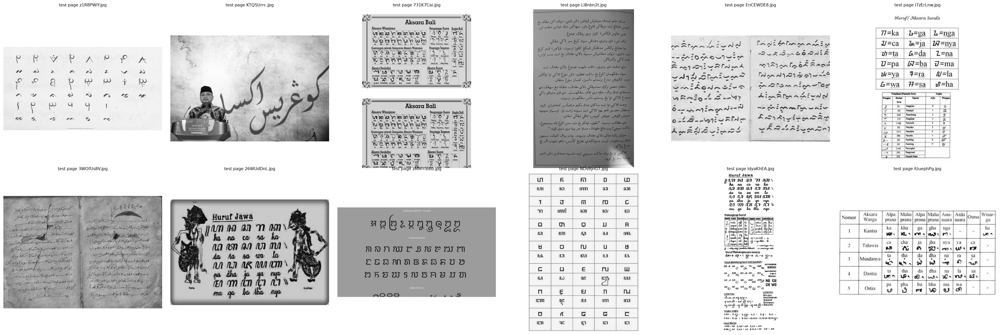

train clean  n=14481 ink median=0.143  blank(<0.5%)=0.01%  >50% black=0.23%  mean grey=215.2


val corrupt  n=13655 ink median=0.145  blank(<0.5%)=0.09%  >50% black=0.54%  mean grey=212.8


test         n= 3121 ink median=0.179  blank(<0.5%)=0.06%  >50% black=3.36%  mean grey=202.3
train page   n=  199 ink median=0.088  blank(<0.5%)=1.01%  >50% black=8.54%  mean grey=202.3
test page    n=  300 ink median=0.085  blank(<0.5%)=0.33%  >50% black=4.33%  mean grey=204.5
sampler fold0: 221 micro-batch (177 non-page x16, 44 page x4)


In [37]:
# visual check 1: non-page seperti v2 (raw | clean canvas | train view | val terkorupsi)
ds_vis = TrainDS(np.arange(len(train)))
fig, axes = plt.subplots(len(LABELS), 4, figsize=(28, 1.8 * len(LABELS)))
for r, lab in enumerate(LABELS):
    j = train.index[(train.label == lab) & ~train_is_page].to_series().sample(1, random_state=r).iloc[0]
    row = axes[r]; x, _ = ds_vis[j]
    row[0].imshow(train_raw[j]); row[0].set_title(f'{lab} raw {train.image_id[j]}', fontsize=8)
    row[1].imshow(clean_tiles[clean_owner == j][0], cmap='gray', vmin=0, vmax=255); row[1].set_title('clean canvas (eval)', fontsize=8)
    row[2].imshow(x[0], cmap='gray', vmin=0, vmax=255); row[2].set_title('train view (corrupt+preprocess)', fontsize=8)
    row[3].imshow(cor_tiles[cor_owner == j][0], cmap='gray', vmin=0, vmax=255); row[3].set_title('val terkorupsi (fixed)', fontsize=8)
    for a in row: a.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'samples_train_nonpage.png', dpi=60); plt.show(); plt.close(fig)

# visual check 2: page per kelas (raw | page_eval | 2x page_train)
fig, axes = plt.subplots(len(LABELS), 4, figsize=(20, 5 * len(LABELS)))
for r, lab in enumerate(LABELS):
    j = train.index[(train.label == lab) & train_is_page].to_series().sample(1, random_state=r).iloc[0]
    row = axes[r]
    row[0].imshow(train_raw[j]); row[0].set_title(f'{lab} page raw {train.image_id[j]}', fontsize=9)
    row[1].imshow(train_page[train_page_owner == j][0], cmap='gray', vmin=0, vmax=255); row[1].set_title(f'page_eval {PAGE_S}', fontsize=9)
    for c in range(2):
        ds_vis.epoch = c
        row[2 + c].imshow(ds_vis[j][0][0], cmap='gray', vmin=0, vmax=255); row[2 + c].set_title(f'page_train epoch {c}', fontsize=9)
    for a in row: a.axis('off')
ds_vis.epoch = 0
plt.tight_layout(); plt.savefig(OUT / 'samples_train_page.png', dpi=50); plt.show(); plt.close(fig)

fig, axes = plt.subplots(2, 6, figsize=(30, 10))
for a, k in zip(axes.ravel(), np.random.default_rng(0).choice(len(test_page), 12, replace=False)):
    a.imshow(test_page[k], cmap='gray', vmin=0, vmax=255); a.set_title(f'test page {test.image_id[test_page_owner[k]]}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'samples_test_page.png', dpi=45); plt.show(); plt.close(fig)

ink = lambda t: (t < 128).mean(axis=(1, 2))
for name, t in [('train clean', clean_tiles), ('val corrupt', cor_tiles), ('test', test_tiles), ('train page', train_page), ('test page', test_page)]:
    f = ink(t)
    print(f'{name:12s} n={len(t):5d} ink median={np.median(f):.3f}  blank(<0.5%)={np.mean(f < .005):.2%}  >50% black={np.mean(f > .5):.2%}  mean grey={t.mean():.1f}')
smp = MixedBatchSampler(np.where(train.fold != 0)[0], seed=SEED)
print(f'sampler fold0: {len(smp)} micro-batch ({smp.n_np} non-page x{MICRO_BATCH}, {smp.n_pg} page x{PAGE_MB})')
assert x.shape == (1, H, W) and x.dtype == torch.uint8 and ds_vis[int(train_page_owner[0])][0].shape == (1, PAGE_S, PAGE_S)

## [9.5] Model dan training per fold

In [38]:
def make_model():
    # dynamic_img_size: DINOv3 memakai RoPE -> 160x640 dan 640x640 dilayani model yang sama tanpa interpolasi pos-embed
    m = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABELS), img_size=(H, W), global_pool='token', dynamic_img_size=True)
    if GRAD_CKPT:
        m.set_grad_checkpointing(True)
    return m.to(DEVICE)


def make_optimizer(model):
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    groups = param_groups_layer_decay(model, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY, no_weight_decay_list=model.no_weight_decay())
    for g in groups:
        g['params'] = [p for p in g['params'] if id(p) not in head_ids]
    groups = [g for g in groups if g['params']]
    groups.append({'params': list(model.get_classifier().parameters()), 'weight_decay': WEIGHT_DECAY, 'lr_scale': HEAD_LR / BASE_LR})
    for g in groups:
        g['base_lr'] = BASE_LR * g.get('lr_scale', 1.0); g['lr'] = g['base_lr']
    assert sum(p.numel() for g in groups for p in g['params']) == sum(p.numel() for p in model.parameters())
    return torch.optim.AdamW(groups, lr=BASE_LR, fused=True)


def macro_f1(y, logits):
    return f1_score(y, logits.argmax(1), labels=list(range(len(LABELS))), average='macro', zero_division=0)


def val_groups(va_idx, corrupt):
    t, o = (cor_tiles, cor_owner) if corrupt else (clean_tiles, clean_owner)
    return [subset_tiles(t, o, va_idx), subset_tiles(train_page, train_page_owner, va_idx)]  # page val selalu bersih (page test bersih, eda/23)


def run_fold(k):
    tag = f'fold{k}'
    done = OUT / f'{tag}_test_logits.npy'
    if done.exists():
        print(f'{tag}: sudah selesai, skip (hapus {done.name} untuk ulang)'); return
    tr_idx, va_idx = np.where(train.fold != k)[0], np.where(train.fold == k)[0]
    seed_all(SEED + k)
    model, t_start = make_model(), time.time()
    opt = make_optimizer(model)
    counts = np.bincount(y_all[tr_idx], minlength=len(LABELS))
    cw = 1 / np.sqrt(counts); cw = cw / cw.mean()
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=DEVICE), label_smoothing=LABEL_SMOOTHING)
    sampler = MixedBatchSampler(tr_idx, seed=SEED * 100 + k)
    steps_per_epoch = len(sampler) // ACCUM
    total, warm = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
    def lr_factor(step):
        if step < warm:
            return (step + 1) / warm
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warm) / max(1, total - warm))))
    vc, vx, y_va = val_groups(va_idx, False), val_groups(va_idx, True), y_all[va_idx]
    va_page = train_is_page[va_idx]
    ds = TrainDS(tr_idx, seed=SEED)
    best, best_state, stale, step, hist = -1.0, None, 0, 0, []
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(EPOCHS):
        ds.epoch = sampler.epoch = epoch
        loader = DataLoader(ds, batch_sampler=sampler, num_workers=NUM_WORKERS, pin_memory=True, prefetch_factor=4)
        model.train(); opt.zero_grad(set_to_none=True)
        t0, loss_sum, seen, pg_loss, pg_n = time.time(), 0.0, 0, 0.0, 0
        for it, (x, y) in enumerate(loader, 1):
            is_pg = x.shape[-2] != H
            x, y = gpu_norm(x.to(DEVICE, non_blocking=True)), y.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                logits = model(x)
            loss = crit(logits.float(), y)
            assert torch.isfinite(loss), f'loss non-finite {tag} epoch {epoch} iter {it}'
            (loss / ACCUM).backward()
            if it % ACCUM == 0:
                for g in opt.param_groups:
                    g['lr'] = g['base_lr'] * lr_factor(step)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); opt.zero_grad(set_to_none=True); step += 1
            loss_sum += loss.item() * len(y); seen += len(y)
            if is_pg:
                pg_loss += loss.item() * len(y); pg_n += len(y)
        lc = predict_logits(model, vc, len(va_idx)); lx = predict_logits(model, vx, len(va_idx))
        rec = dict(fold=k, epoch=epoch + 1, loss=loss_sum / seen, page_loss=pg_loss / max(1, pg_n), f1_clean=macro_f1(y_va, lc), f1_corrupt=macro_f1(y_va, lx),
                   page_acc=float((lc.argmax(1)[va_page] == y_va[va_page]).mean()), nonpage_acc_corrupt=float((lx.argmax(1)[~va_page] == y_va[~va_page]).mean()),
                   train_s=round(time.time() - t0), imgs_per_s=round(seen / (time.time() - t0)), lr_top=BASE_LR * lr_factor(step))
        hist.append(rec); print(json.dumps(rec), flush=True)
        if rec['f1_corrupt'] > best:  # v2 rule; f1_corrupt = non-page terkorupsi + page bersih = mirip test
            best, stale = rec['f1_corrupt'], 0
            best_state = {n: v.detach().to('cpu', copy=True) for n, v in model.state_dict().items()}
            best_logits, best_epoch = (lc, lx), epoch + 1
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f'early stop {tag} epoch {epoch + 1}'); break
    model.load_state_dict(best_state)
    np.save(OUT / f'{tag}_val_idx.npy', va_idx)
    np.save(OUT / f'{tag}_oof_clean_logits.npy', best_logits[0]); np.save(OUT / f'{tag}_oof_corrupt_logits.npy', best_logits[1])
    pd.DataFrame(hist).to_csv(OUT / f'{tag}_history.csv', index=False)
    np.save(done, predict_logits(model, [(test_tiles, test_owner), (test_page, test_page_owner)], len(test)))  # ditulis terakhir = penanda selesai
    print(f'{tag}: best f1_corrupt={best:.4f} @{best_epoch} | {(time.time() - t_start) / 60:.1f} min | peak VRAM {torch.cuda.max_memory_allocated() / 2**30:.1f} GB')
    del model, opt, best_state
    gc.collect(); torch.cuda.empty_cache()

Training lima fold v5 dengan sampler homogen; artefak per fold sama dengan v2.

In [39]:
for k in FOLDS:
    run_fold(k)

{"fold": 0, "epoch": 1, "loss": 1.311773585512283, "page_loss": 1.4503471038558267, "f1_clean": 0.9576204985675334, "f1_corrupt": 0.9499104350256484, "page_acc": 0.7586206896551724, "nonpage_acc_corrupt": 0.9627586206896551, "train_s": 45, "imgs_per_s": 67, "lr_top": 4e-05}


{"fold": 0, "epoch": 2, "loss": 0.5272121439747354, "page_loss": 0.5920204235748812, "f1_clean": 0.9848503990140085, "f1_corrupt": 0.9787849731754458, "page_acc": 0.8620689655172413, "nonpage_acc_corrupt": 0.9848275862068966, "train_s": 45, "imgs_per_s": 67, "lr_top": 3.919796087756705e-05}


{"fold": 0, "epoch": 3, "loss": 0.5080558543113318, "page_loss": 0.5968486388975923, "f1_clean": 0.979356050085384, "f1_corrupt": 0.9756601311677163, "page_acc": 0.7586206896551724, "nonpage_acc_corrupt": 0.9875862068965517, "train_s": 45, "imgs_per_s": 67, "lr_top": 3.685681995005739e-05}


{"fold": 0, "epoch": 4, "loss": 0.5009649040058572, "page_loss": 0.5056260079145432, "f1_clean": 0.9838959146478189, "f1_corrupt": 0.9807606601127122, "page_acc": 0.896551724137931, "nonpage_acc_corrupt": 0.9862068965517241, "train_s": 46, "imgs_per_s": 66, "lr_top": 3.316624253211665e-05}


{"fold": 0, "epoch": 5, "loss": 0.4905100851616961, "page_loss": 0.46150921149687335, "f1_clean": 0.9791035578655201, "f1_corrupt": 0.9749518805550934, "page_acc": 0.7931034482758621, "nonpage_acc_corrupt": 0.9848275862068966, "train_s": 45, "imgs_per_s": 66, "lr_top": 2.8425217257437355e-05}


...

{"fold": 4, "epoch": 9, "loss": 0.4757559122468429, "page_loss": 0.45279555090449075, "f1_clean": 0.9774363183713239, "f1_corrupt": 0.9740492233832841, "page_acc": 0.8333333333333334, "nonpage_acc_corrupt": 0.9846796657381616, "train_s": 45, "imgs_per_s": 67, "lr_top": 7.233757467883358e-06}


{"fold": 4, "epoch": 10, "loss": 0.4783181065999011, "page_loss": 0.44269655035300687, "f1_clean": 0.9784010189579281, "f1_corrupt": 0.9750085263863956, "page_acc": 0.8333333333333334, "nonpage_acc_corrupt": 0.9860724233983287, "train_s": 45, "imgs_per_s": 67, "lr_top": 3.54318004994261e-06}


{"fold": 4, "epoch": 11, "loss": 0.4787096119037381, "page_loss": 0.4472706852988763, "f1_clean": 0.9768328119123019, "f1_corrupt": 0.9734422380701703, "page_acc": 0.8333333333333334, "nonpage_acc_corrupt": 0.9846796657381616, "train_s": 45, "imgs_per_s": 67, "lr_top": 1.2020391224329545e-06}


{"fold": 4, "epoch": 12, "loss": 0.4796565201468569, "page_loss": 0.4454456994479353, "f1_clean": 0.9795481432743952, "f1_corrupt": 0.9761501873033505, "page_acc": 0.8611111111111112, "nonpage_acc_corrupt": 0.9860724233983287, "train_s": 45, "imgs_per_s": 67, "lr_top": 4.0000000000000003e-07}


fold4: best f1_corrupt=0.9762 @12 | 9.3 min | peak VRAM 12.1 GB


## [9.6] OOF v5 vs v2 per jenis gambar

,run,f1_clean,f1_corrupt,f1_testlike,page_acc,line_acc,block_acc,glyph_acc
0,v5,0.9853,0.9800,0.9800,0.8442,0.9936,0.9658,0.9819
1,v2,0.9787,0.9726,0.9761,0.8040,0.9926,0.9658,0.9728


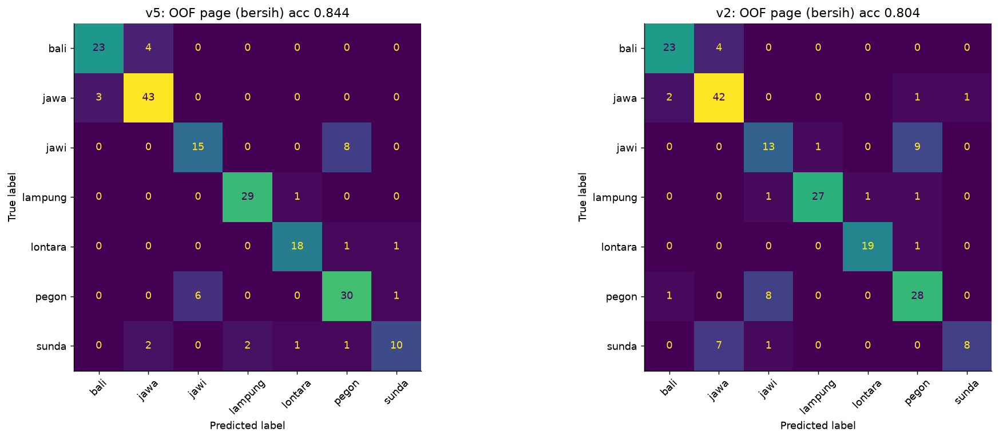

,epoch,loss,page_loss,f1_clean,f1_corrupt,page_acc,nonpage_acc_corrupt,train_s,imgs_per_s,lr_top
fold,,,,,,,,,,
0,7.0,0.4928,0.4795,0.9880,0.9873,0.8621,0.9931,45.0,66.0,0.0
1,9.0,0.4732,0.4567,0.9813,0.9752,0.8113,0.9886,46.0,67.0,0.0
2,4.0,0.4967,0.4913,0.9910,0.9825,0.8824,0.9875,45.0,67.0,0.0
3,9.0,0.4716,0.4503,0.9865,0.9786,0.8298,0.9915,45.0,67.0,0.0
4,12.0,0.4797,0.4454,0.9795,0.9762,0.8611,0.9861,45.0,67.0,0.0


In [40]:
def ctype_of(p):
    w, h = orig_size(p)
    return 'page' if h >= 250 else ('line' if w / h >= 2 else ('block' if w >= 80 else 'glyph'))
ctype = np.array([ctype_of(p) for p in train.path])
done_folds = [k for k in FOLDS if (OUT / f'fold{k}_test_logits.npy').exists()]
assert done_folds, 'belum ada fold selesai'
sm = lambda a: torch.softmax(torch.from_numpy(a), 1).numpy()


def load_oof(d):
    idx = np.concatenate([np.load(d / f'fold{k}_val_idx.npy') for k in done_folds])
    return idx, np.concatenate([np.load(d / f'fold{k}_oof_clean_logits.npy') for k in done_folds]), np.concatenate([np.load(d / f'fold{k}_oof_corrupt_logits.npy') for k in done_folds])


runs = {'v5': load_oof(OUT)}
V2 = ROOT / 'results/v2/main'
if all((V2 / f'fold{k}_oof_clean_logits.npy').exists() for k in done_folds):
    runs['v2'] = load_oof(V2)
rows = []
for name, (idx, lc, lx) in runs.items():
    y, ct = y_all[idx], ctype[idx]
    tl = np.where((ct == 'page')[:, None], lc, lx)  # mirip test: page bersih, sisanya terkorupsi
    r = dict(run=name, f1_clean=macro_f1(y, lc), f1_corrupt=macro_f1(y, lx), f1_testlike=macro_f1(y, tl))
    for t in ['page', 'line', 'block', 'glyph']:
        m = ct == t
        r[f'{t}_acc'] = (tl.argmax(1)[m] == y[m]).mean()
    rows.append(r)
oof_tab = pd.DataFrame(rows).round(4); display(oof_tab); oof_tab.to_csv(OUT / 'oof_by_type.csv', index=False)
idx, lc, lx = runs['v5']; m = ctype[idx] == 'page'
fig, ax = plt.subplots(1, len(runs), figsize=(8 * len(runs), 6), squeeze=False)
for a, (name, (i2, c2, _)) in zip(ax[0], runs.items()):
    mm = ctype[i2] == 'page'
    ConfusionMatrixDisplay(confusion_matrix(y_all[i2][mm], c2.argmax(1)[mm], labels=range(len(LABELS))), display_labels=LABELS).plot(ax=a, xticks_rotation=45, colorbar=False)
    a.set_title(f'{name}: OOF page (bersih) acc {(c2.argmax(1)[mm] == y_all[i2][mm]).mean():.3f}')
plt.tight_layout(); plt.savefig(OUT / 'oof_page_confusion.png', dpi=80); plt.show(); plt.close(fig)
display(pd.concat([pd.read_csv(OUT / f'fold{k}_history.csv') for k in done_folds]).groupby('fold').apply(lambda h: h.loc[h.f1_corrupt.idxmax()]).round(4))

Submission A (v5 penuh) dan B (hybrid: page v5, non-page v2). Selisih baris terhadap v2 dicetak per jenis gambar, dan page yang berubah ditampilkan untuk dicek visual.

,A_v5,B_hybrid,v2_LB0.915
A_v5,0,11,43
B_hybrid,11,0,32
v2_LB0.915,43,32,0


A_v5 vs v2: 43 baris beda | per tipe {'page': 32, 'line': 10, 'block': 1}
   transisi v2 -> A_v5 {'jawa->sunda': 5, 'jawa->bali': 5, 'bali->jawa': 5, 'jawi->pegon': 5, 'jawi->lampung': 3, 'pegon->jawi': 3, 'lontara->jawi': 2, 'sunda->jawa': 2, 'lampung->jawa': 2, 'jawa->jawi': 1}
B_hybrid vs v2: 32 baris beda | per tipe {'page': 32}
   transisi v2 -> B_hybrid {'jawa->sunda': 5, 'jawa->bali': 4, 'jawi->lampung': 3, 'bali->jawa': 3, 'pegon->jawi': 3, 'lampung->jawa': 2, 'jawa->jawi': 1, 'pegon->lontara': 1, 'pegon->sunda': 1, 'lampung->pegon': 1}


,A_v5,B_hybrid,v2_LB0.915
bali,8.8,8.8,8.8
jawa,18.8,18.6,18.9
jawi,13.8,14.1,13.9
lampung,18.9,19.0,19.0
lontara,9.3,9.3,9.3
pegon,16.7,16.4,16.7
sunda,13.8,13.9,13.4


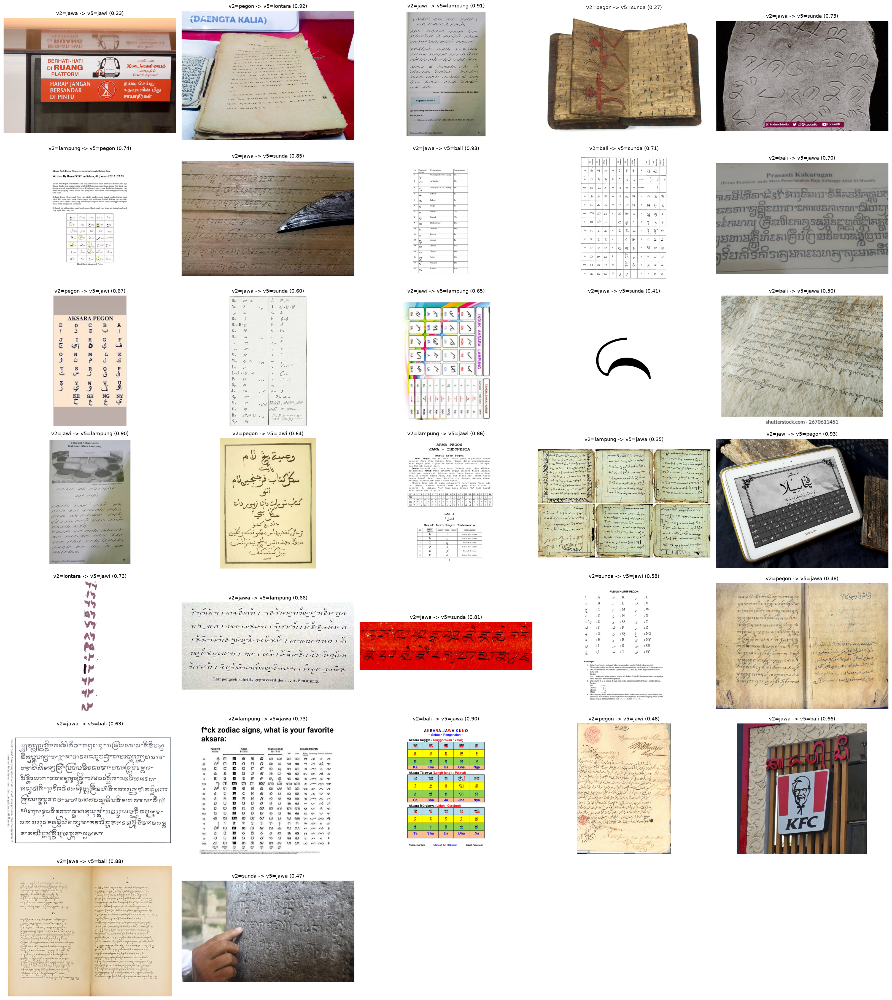

SELESAI -> ['submission_A_v5.csv', 'submission_B_hybrid.csv']


In [41]:
test_ctype = np.array([ctype_of(p) for p in test.path])
p5 = np.mean([sm(np.load(OUT / f'fold{k}_test_logits.npy')) for k in done_folds], 0)
assert p5.shape == (len(test), len(LABELS)) and np.allclose(p5.sum(1), 1)


def write(p, name):
    pred = np.array(LABELS, dtype=object)[p.argmax(1)]
    if USE_TWINS and len(twins):
        tw = test.image_id.map(twins.set_index('image_id').train_label); m = tw.notna().values
        pred[m] = tw[m].values
    sub = sample_sub[['image_id']].merge(pd.DataFrame({'image_id': test.image_id, 'label': pred}), on='image_id', how='left')
    assert len(sub) == len(sample_sub) and sub.label.notna().all() and set(sub.label) <= set(LABELS)
    sub.to_csv(OUT / name, index=False)
    pd.DataFrame(p, columns=LABELS).assign(image_id=test.image_id.values).to_csv(OUT / name.replace('submission', 'probs'), index=False)
    return sub.set_index('image_id').label.reindex(test.image_id).values


subs = {'A_v5': write(p5, 'submission_A_v5.csv')}
v2_m = [V2 / f'fold{k}_test_logits.npy' for k in range(5)]  # selalu 5 fold v2 (= submission LB 0.91514), terlepas dari FOLDS
if all(p.exists() for p in v2_m):
    p2 = np.mean([sm(np.load(p)) for p in v2_m], 0)
    subs['B_hybrid'] = write(np.where(test_is_page[:, None], p5, p2), 'submission_B_hybrid.csv')
for v, p in [('v2_LB0.915', V2 / 'submission.csv'), ('v3_LB0.891', ROOT / 'results/v3/main/submission.csv')]:
    if p.exists():
        subs[v] = pd.read_csv(p).set_index('image_id').label.reindex(test.image_id).values
names = list(subs)
display(pd.DataFrame([[int((subs[a] != subs[b]).sum()) for b in names] for a in names], index=names, columns=names))
if 'v2_LB0.915' in subs:
    for n in [x for x in names if x[0] in 'AB']:
        d = subs[n] != subs['v2_LB0.915']
        print(f'{n} vs v2: {d.sum()} baris beda | per tipe {pd.Series(test_ctype[d]).value_counts().to_dict()}')
        print('   transisi v2 -> ' + n, pd.Series([f'{a}->{b}' for a, b in zip(subs['v2_LB0.915'][d], subs[n][d])]).value_counts().head(10).to_dict())
display(pd.DataFrame({n: pd.Series(subs[n]).value_counts(normalize=True) * 100 for n in names}).reindex(LABELS).round(1))

# grid page yang berubah vs v2 (cek visual, bukan label)
if 'v2_LB0.915' in subs:
    ch = np.where((subs['A_v5'] != subs['v2_LB0.915']) & test_is_page)[0][:40]
    if len(ch):
        fig, axes = plt.subplots(int(np.ceil(len(ch) / 5)), 5, figsize=(25, 4 * int(np.ceil(len(ch) / 5))), squeeze=False)
        for a in axes.ravel(): a.axis('off')
        for a, j in zip(axes.ravel(), ch):
            a.imshow(Image.open(test.path[j]).convert('RGB')); a.set_title(f'v2={subs["v2_LB0.915"][j]} -> v5={subs["A_v5"][j]} ({p5[j].max():.2f})', fontsize=10)
        plt.tight_layout(); plt.savefig(OUT / 'changed_pages.png', dpi=45); plt.show(); plt.close(fig)

config = {k: v for k, v in dict(globals()).items() if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple))}
config.update(torch=torch.__version__, timm=timm.__version__, python=platform.python_version(), gpu=torch.cuda.get_device_name())
(OUT / 'config.json').write_text(json.dumps(config, indent=2, default=str))
print('SELESAI ->', sorted(p.name for p in OUT.glob('submission_*.csv')))

#### Result dan Decision

> Hipotesis terbukti di segmen yang dituju: page benar naik dari 160 (v2) ke 168 dari 199 (0,804 ke 0,844), sedangkan baris tetap 0,993.

> Pada run ini v5 juga sedikit lebih baik di non-page (38 vs 44 error). Pada run LB urutannya terbalik (44 vs 41), sehingga selisih non-page antar kedua model berada dalam noise antar run; yang konsisten di kedua run hanya kenaikan page.

**Decision: KEEP** untuk page.

---

# Error Analysis dan Perakitan Hybrid <a name="10"></a>

---

Hybrid B memakai probabilitas page dari v5 dan non-page dari v2. OOF-nya dirakit dengan aturan yang sama: page dinilai pada view bersih v5, non-page pada view terkorupsi v2.

In [42]:
def load_oof_run(d):
    idx = np.concatenate([np.load(d / f'fold{k}_val_idx.npy') for k in range(5)])
    order = np.argsort(idx)
    c = np.concatenate([np.load(d / f'fold{k}_oof_clean_logits.npy') for k in range(5)])[order]
    x = np.concatenate([np.load(d / f'fold{k}_oof_corrupt_logits.npy') for k in range(5)])[order]
    return sm(c), sm(x)


R2, R5 = ROOT / 'results/v2/main', ROOT / 'results/v5/main'
c2, x2 = load_oof_run(R2)
c5, x5 = load_oof_run(R5)
is_pg = train_is_page
P_v2 = np.where(is_pg[:, None], c2, x2)
P_v5 = np.where(is_pg[:, None], c5, x5)
P_hb = np.where(is_pg[:, None], c5, x2)
fold_of = train.fold.to_numpy()


def summary(P, name):
    pr = P.argmax(1)
    per_fold = [f1_score(y_all[fold_of == k], pr[fold_of == k], average='macro') for k in range(5)]
    return dict(model=name, macro_f1=f1_score(y_all, pr, average='macro'), std_fold=np.std(per_fold, ddof=1),
                fold_terburuk=min(per_fold), page_benar=int((pr[is_pg] == y_all[is_pg]).sum()),
                error_nonpage=int((pr[~is_pg] != y_all[~is_pg]).sum()),
                f1_jawi=f1_score(y_all, pr, labels=[2], average=None)[0], f1_pegon=f1_score(y_all, pr, labels=[5], average=None)[0])


comp = pd.DataFrame([summary(P_v2, 'v2'), summary(P_v5, 'v5'), summary(P_hb, 'hybrid B')]).round(4)
display(comp)
fold_table = pd.DataFrame({
    'n_val': np.bincount(fold_of),
    'macro_f1_hybrid': [f1_score(y_all[fold_of == k], P_hb[fold_of == k].argmax(1), average='macro') for k in range(5)],
    'page_benar': [int((P_hb[(fold_of == k) & is_pg].argmax(1) == y_all[(fold_of == k) & is_pg]).sum()) for k in range(5)],
    'page_n': [int(((fold_of == k) & is_pg).sum()) for k in range(5)],
}).round(4)
display(fold_table)
print(f"mean {fold_table.macro_f1_hybrid.mean():.4f} | std {fold_table.macro_f1_hybrid.std(ddof=1):.4f} | "
      f"terburuk fold {fold_table.macro_f1_hybrid.idxmin()} | terbaik fold {fold_table.macro_f1_hybrid.idxmax()}")

,model,macro_f1,std_fold,fold_terburuk,page_benar,error_nonpage,f1_jawi,f1_pegon
0,v2,0.9761,0.0038,0.9696,160,44,0.9652,0.9305
1,v5,0.9800,0.0050,0.9752,168,38,0.9744,0.9496
2,hybrid B,0.9780,0.0056,0.9690,168,44,0.9690,0.9371


,n_val,macro_f1_hybrid,page_benar,page_n
0,754,0.9831,25,29
1,754,0.9769,43,53
2,755,0.9824,30,34
3,754,0.9784,39,47
4,754,0.9690,31,36


mean 0.9780 | std 0.0057 | terburuk fold 4 | terbaik fold 0


#### Insights

> Hybrid B (page v5, non-page v2) mencapai OOF macro F1 0,9780 dengan std antar fold 0,0057 dan fold terburuk 0,9690 (fold 4). Fold 4 juga fold terburuk untuk v2, jadi penurunannya berasal dari data fold itu, bukan dari routing.

> Pada run ini v5 penuh (0,9800) sedikit di atas hybrid karena non-page v5 lebih baik; pada run LB hybrid yang unggul (0,9801 vs 0,9798). Selisih 0,002 ini lebih kecil dari std antar fold, sehingga keputusan tidak diambil dari OOF: hybrid dipakai karena terbukti di public LB (0,91820) dan mengisolasi satu-satunya perubahan yang konsisten, yaitu page.

## [10.1] Di mana hybrid gagal: kelas, pasangan, dan jenis gambar

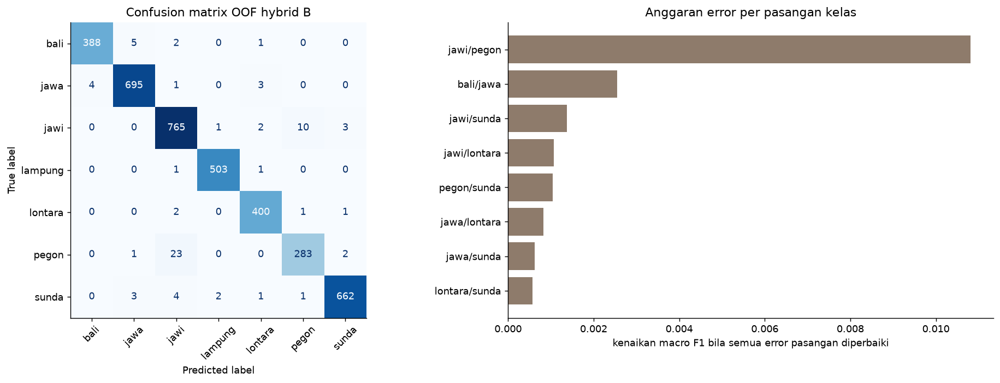

,n,akurasi
jenis,,
block,409,0.9658
glyph,331,0.9728
line,2832,0.9926
page,199,0.8442


In [43]:
pr = P_hb.argmax(1)
cm = confusion_matrix(y_all, pr, labels=range(len(LABELS)))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=axes[0], xticks_rotation=45, colorbar=False, cmap='Blues')
axes[0].set_title('Confusion matrix OOF hybrid B')
rows = []
for a in range(7):
    for b in range(a + 1, 7):
        m = ((y_all == a) & (pr == b)) | ((y_all == b) & (pr == a))
        if m.sum():
            fix = pr.copy()
            fix[m] = y_all[m]
            rows.append((f'{LABELS[a]}/{LABELS[b]}', int(m.sum()), f1_score(y_all, fix, average='macro') - f1_score(y_all, pr, average='macro')))
budget = pd.DataFrame(rows, columns=['pasangan', 'n_error', 'gain_bila_benar']).sort_values('gain_bila_benar', ascending=False).head(8)
axes[1].barh(budget.pasangan[::-1], budget.gain_bila_benar[::-1], color='#8E7B6B')
axes[1].set_xlabel('kenaikan macro F1 bila semua error pasangan diperbaiki')
axes[1].set_title('Anggaran error per pasangan kelas')
for s in ('top', 'right'):
    axes[1].spines[s].set_visible(False)
fig.tight_layout()
plt.show()
ct_tab = pd.DataFrame({'jenis': ctype, 'benar': pr == y_all}).groupby('jenis').benar.agg(['size', 'mean']).rename(columns={'size': 'n', 'mean': 'akurasi'})
display(ct_tab.round(4))

#### Insights

> Jawi/Pegon adalah sumber kerugian terbesar: 33 error dan kenaikan macro F1 +0,0108 bila semuanya benar, lebih dari empat kali pasangan berikutnya (Bali/Jawa +0,0025). Arahnya tidak seimbang: 23 Pegon diprediksi Jawi, 10 Jawi diprediksi Pegon; model condong ke kelas yang lebih besar.

> Per jenis gambar, baris hampir sempurna (0,993), block dan glyph sekitar 0,97, dan page 0,844. Dua segmen terlemah, page dan Jawi/Pegon, adalah dua masalah yang disebut EDA di Bagian 5.

## [10.2] Apa yang diubah view page: v2 vs v5 pada 199 page

page benar v2 160 | v5 168 | diperbaiki v5 15 | dirusak v5 7


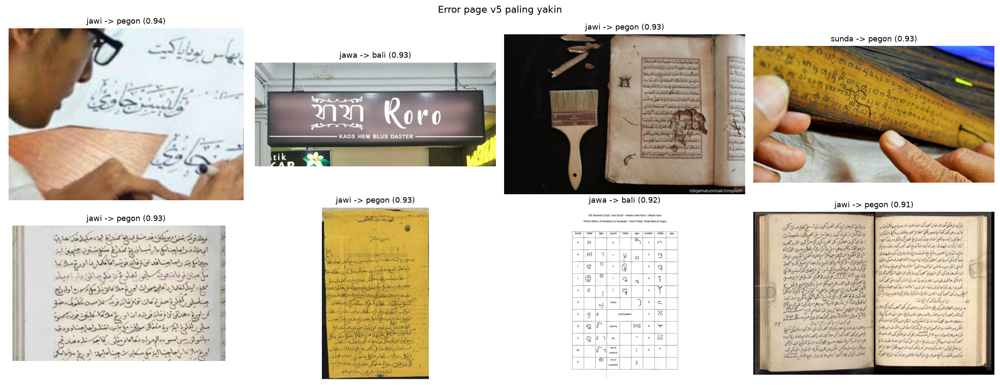

In [44]:
ok2, ok5 = c2.argmax(1) == y_all, c5.argmax(1) == y_all
print(f'page benar v2 {int(ok2[is_pg].sum())} | v5 {int(ok5[is_pg].sum())} | diperbaiki v5 {int((ok5 & ~ok2 & is_pg).sum())} | '
      f'dirusak v5 {int((~ok5 & ok2 & is_pg).sum())}')
err5 = np.where(~ok5 & is_pg)[0]
err5 = err5[np.argsort(-c5[err5].max(1))][:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for a, j in zip(axes.ravel(), err5):
    im = Image.open(train.path[j]).convert('RGB')
    im.thumbnail((500, 500))
    a.imshow(im)
    a.set_title(f'{LABELS[y_all[j]]} -> {LABELS[c5[j].argmax()]} ({c5[j].max():.2f})', fontsize=10)
    a.axis('off')
for a in axes.ravel()[len(err5):]:
    a.axis('off')
fig.suptitle('Error page v5 paling yakin')
fig.tight_layout()
plt.show()

#### Insights

> View 640 memperbaiki 15 page dan merusak 7, bersih +8. Page yang tetap salah dengan keyakinan tinggi (0,91 sampai 0,94) didominasi naskah Jawi yang diprediksi Pegon, ditambah papan nama dan tabel aksara Jawa yang diprediksi Bali.

> Pada naskah Arab-Melayu seperti ini, bahasa hanya bisa dibaca dari isi teks. Error yang seyakin ini tidak bisa diperbaiki dengan menggeser ambang; ini batas dari informasi visual yang tersedia.

## [10.3] Riwayat training dan stabilitas epoch

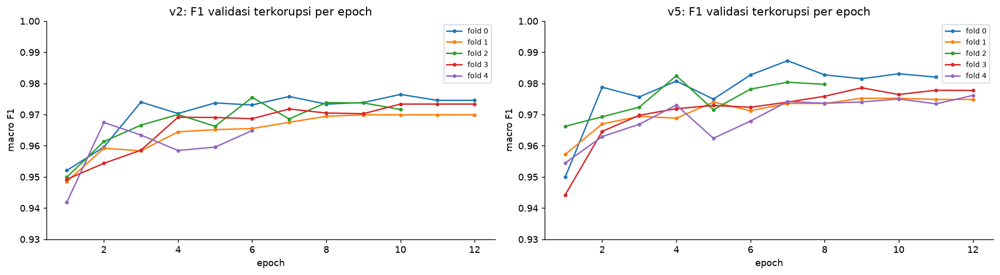

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (name, d, col) in zip(axes, [('v2', R2, 'f1_corrupt'), ('v5', R5, 'f1_corrupt')]):
    for k in range(5):
        h = pd.read_csv(d / f'fold{k}_history.csv')
        ax.plot(h.epoch, h[col], marker='o', ms=3, label=f'fold {k}')
    ax.set(title=f'{name}: F1 validasi terkorupsi per epoch', xlabel='epoch', ylabel='macro F1', ylim=(0.93, 1.0))
    ax.legend(fontsize=8)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

#### Insights

> v2 naik cepat dalam 3 sampai 4 epoch lalu mendatar di sekitar 0,97; beberapa fold memuncak di epoch 10. v5 lebih berayun di epoch awal karena micro-batch page ikut memengaruhi, lalu stabil di 0,975 sampai 0,985. Tidak ada fold yang turun tajam setelah puncak, sehingga patience 4 dan cosine schedule cukup untuk mencegah overfit.

---

# Experiment Registry dan Negative Results <a name="11"></a>

---

## [11.1] Experiment registry

Semua baris memakai fold yang sama kecuali v1. Angka OOF diambil dari run yang dikirim ke LB; run ulang di notebook ini memberi v2 0,9761, v5 0,9800, hybrid 0,9780 (Bagian 10). Public LB dari Kaggle.

| ID | Family | Main idea | OOF testlike | Public LB | Status |
|---|---|---|---:|---:|---|
| v1 | baseline | DINOv3 ViT-L, letterbox, holdout acak | holdout 0,976 | 0,86289 | REJECT |
| v2 | representasi | korupsi sebelum preprocessing, group 5-fold | 0,9771 | 0,91514 | KEEP |
| v3 | page | tile page dibaca model baris | 0,9740 | 0,89077 | REJECT |
| v5 | page | view page 640x640 | 0,9798 | - | KEEP (page) |
| **hybrid B** | routing | page v5 + non-page v2 | **0,9801** | **0,91820** | **FINAL** |
| v6 | preprocessing | stretch dari piksel konten | 0,9819 | 0,91273 | REJECT |
| v7 | retrieval | ArcFace + SupCon, kNN | - | 0,88808 | REJECT |
| v5+v11 | ensemble | rata-rata dengan SigLIP2 NaFlex | 0,9836 | 0,91815 | REJECT (LB sama) |
| ViT-7B | backbone | resep v5, ViT-7B LoRA, holdout fold 3 | fold3 0,9841 | 0,90966 | REJECT |

## [11.2] Negative results

| Eksperimen | Harapan | Hasil | Alasan ditolak |
|---|---|---|---|
| Tile page (v3) | membaca huruf page lebih rinci | LB -0,024 | label page mengikuti topik gambar, bukan huruf lokal |
| Stretch dari piksel konten (v6) | teks abu tidak terhapus | OOF naik, LB -0,0055 | salah pada baris yang diubah |
| Bobot kelas 1/n, koreksi prior | macro F1 lebih seimbang | -0,0049 / -0,0021 nested | error bukan di batas keputusan |
| ConvNeXtV2-L, EfficientNetV2-L | diversitas CNN | fold uji 0,966 / 0,878 | kalah jauh dari ViT pretrained skala web |
| kNN embedding fine-tuned | memakai tetangga sedokumen | ensemble turun | tidak menambah informasi |
| Halaman sintetis dari potongan baris | menambah page | AUC domain 0,995 | tidak mirip page asli |
| Page specialist SigLIP2, 7 seed | page >= 179/199 | rata-rata 171 | variasi seed +-5 page, tidak ada jawaban baru |
| Probe page beku (RADIO, SigLIP2, EVA-CLIP, DINOv3-H) | sinyal page baru | 148-151/199 | digabung dengan v5 selalu negatif |
| Augmentasi noise mirip test B | robust terhadap noise berat | view keras +0,0013 (CI lewat 0), view bersih -0,0042 | model sudah robust terhadap jenis noise |
| Focal loss (cost-sensitive) | fokus sampel sulit | view keras -0,0046 | tidak konsisten antar fold |
| ViT-7B LoRA | backbone lebih besar | holdout LB 0,90966 | unggul non-page OOF, page tidak berubah, LB turun |

---

# Suspicious Result Audit dan Final Model Selection <a name="12"></a>

---

## [12.1] Suspicious result audit

- [x] Preprocessing tidak melihat validasi: semua operasi per citra, tanpa statistik global.
- [x] Grup duplikat tidak tersebar ke train dan validasi (`assert` di Bagian 6 dan di cell data v2/v5).
- [x] Tidak ada ID, nama berkas, atau format berkas sebagai fitur.
- [x] Tidak ada bobot ensemble atau ambang yang dioptimasi pada OOF yang sama: hybrid adalah routing tetap.
- [ ] Early stopping memakai fold validasi yang sama dengan skornya. Seleksi epoch ini sedikit optimistis untuk semua versi dengan cara yang sama, sehingga perbandingan antarversi tetap adil.
- [ ] Grup duplikat tidak memisahkan buku sumber. Baris dari buku yang sama bisa berada di fold berbeda, sehingga OOF (0,98) jauh di atas LB (0,918). Karena itu keputusan final dikonfirmasi di LB.

### Why this score might be optimistic

> OOF 0,980 vs LB 0,918: test berisi sumber yang tidak pernah dilihat dan korupsi yang lebih berat dari `corrupt()`. Selisih kecil OOF (di bawah 0,005) tidak dianggap berarti; v6 dan v5+v11 contohnya.

### Verification

> Hybrid B dikonfirmasi di public LB (0,91820, tertinggi tim). Notebook ini menjalankan ulang resep yang sama dari awal; selisih kecil terhadap berkas LB berasal dari nondeterminisme GPU, bukan perubahan kode.

## [12.2] Final model selection

| Kandidat | OOF testlike | Public LB | Stabilitas | Risiko | Final |
|---|---:|---:|---|---|---|
| v2 | 0,9771 | 0,91514 | tinggi | rendah | - |
| v5 penuh | 0,9798 | - | tinggi | non-page ikut berubah | - |
| **hybrid B** | **0,9801** | **0,91820** | tinggi | rendah, routing tetap | **dipilih** |
| v5+v11 | 0,9836 | 0,91815 | sedang | ensemble 2 keluarga | - |
| ViT-7B holdout | 0,9841 (fold 3) | 0,90966 | rendah (1 fold) | tinggi | - |

Prioritas pemilihan: validasi yang valid, robust, reproducible, baru skor mentah. Hybrid B adalah satu-satunya kandidat yang naik di LB dengan mekanisme yang jelas (page view) dan tanpa tuning pada OOF.

---

# Final Pipeline dan Submission <a name="13"></a>

---

Berkas `submission_B_hybrid.csv` ditulis oleh cell submission v5 di Bagian 9: probabilitas page dari rata-rata 5 fold v5, non-page dari rata-rata 5 fold v2, lalu twins memakai label train. Cell berikut memeriksa berkas dan menyalinnya sebagai `submission.csv`.

In [46]:
final = pd.read_csv(ROOT / 'results/v5/main/submission_B_hybrid.csv')
ss = pd.read_csv(DATA / 'sample_submission.csv')
assert len(final) == len(ss), 'jumlah baris berbeda'
assert (final.image_id.values == ss.image_id.values).all(), 'urutan ID berbeda'
assert final.label.notna().all() and set(final.label) <= set(LABELS), 'label kosong atau di luar skema'
final.to_csv('submission.csv', index=False)
check = pd.read_csv('submission.csv')
print(f'submission.csv: {len(check)} baris, terbaca ulang OK')
display(check.label.value_counts().rename('jumlah').to_frame().T)

submission.csv: 1220 baris, terbaca ulang OK


label,lampung,jawa,pegon,jawi,sunda,lontara,bali
jumlah,232,227,200,172,169,113,107


#### Insights

> Submission berisi 1.220 baris dengan urutan ID sama dengan `sample_submission.csv`, tanpa label kosong, dan terbaca ulang. Distribusi prediksi: Lampung 232, Jawa 227, Pegon 200, Jawi 172, Sunda 169, Lontara 113, Bali 107.

> Dibanding berkas yang dikirim ke LB (0,91820), prediksi notebook ini sama pada 1.207 dari 1.220 baris (98,9%); 13 baris berbeda karena nondeterminisme GPU saat training ulang.

## [13.1] Artifact contract

Setiap experiment menyimpan OOF dan prediksi test dengan format sama, sehingga perakitan hybrid tidak perlu melatih ulang model.

In [47]:
for d in (R2, R5):
    files = sorted(p.name for p in d.iterdir())
    kinds = pd.Series([re.sub(r'fold\d_', 'fold{k}_', f) for f in files]).value_counts()
    print(f'{d.relative_to(ROOT)}: {len(files)} berkas')
    display(kinds.rename('jumlah').to_frame().T)

results/v2/main: 36 berkas


,fold{k}_history.csv,fold{k}_oof_clean_logits.npy,fold{k}_oof_corrupt_logits.npy,fold{k}_test_logits.npy,fold{k}_val_idx.npy,config.json,fold_metrics.csv,oof_confusion.png,oof_corrupt_per_class.csv,oof_predictions.csv,oof_ratio_buckets.csv,samples_test.png,samples_train.png,submission.csv,summary.json,test_probabilities.csv
jumlah,5,5,5,5,5,1,1,1,1,1,1,1,1,1,1,1


results/v5/main: 36 berkas


,fold{k}_history.csv,fold{k}_oof_clean_logits.npy,fold{k}_oof_corrupt_logits.npy,fold{k}_test_logits.npy,fold{k}_val_idx.npy,changed_pages.png,config.json,oof_by_type.csv,oof_page_confusion.png,probs_A_v5.csv,probs_B_hybrid.csv,samples_test_page.png,samples_train_nonpage.png,samples_train_page.png,submission_A_v5.csv,submission_B_hybrid.csv
jumlah,5,5,5,5,5,1,1,1,1,1,1,1,1,1,1,1


---

# Kesimpulan <a name="14"></a>

---

## What worked

- **Meniru korupsi test sebelum preprocessing** (v2): lompatan terbesar, LB 0,86289 ke 0,91514.
- **View page terpisah 640x640** (v5, dirakit sebagai hybrid B): LB 0,91514 ke 0,91820.
- **Validasi berbasis grup duplikat**: mencegah skor semu seperti holdout acak v1.

## What did not work

Tile page, perbaikan stretch, retrieval, CNN, bobot kelas penuh, page sintetis, backbone 7B, dan augmentasi noise yang lebih berat (Bagian 11).

## Most important signal

Kecocokan distribusi input: model yang melihat test-like view saat training jauh lebih penting dari ukuran backbone.

## Biggest validation risk

OOF tidak memisahkan buku sumber, sehingga OOF 0,98 terlalu optimistis dibanding LB 0,918. Selisih OOF kecil tidak cukup untuk memilih model.

## What we would try next

Pembedaan Jawi/Pegon berbasis bahasa (butuh transkripsi, tidak tersedia) dan validasi yang memisahkan sumber.

#### Catatan

- OOF (0,978) jauh di atas LB (0,918). Test berisi sumber dan korupsi yang tidak sepenuhnya terwakili di train, sehingga angka OOF dibaca sebagai peringkat kasar, bukan estimasi skor test.
- Run ulang dengan kode identik menghasilkan submission yang 98,9% sama. Selisih OOF antar run (sekitar 0,001 sampai 0,002) sama besarnya dengan selisih antar beberapa kandidat model, alasan selisih kecil tidak dipakai untuk memilih model.
- Training memakai 5 fold dengan satu seed; variasi antar seed tidak diukur di notebook ini.

---

# Daftar Pustaka <a name="15"></a>

---

1. Simeoni, O. et al. (2025). *DINOv3*. arXiv:2508.10104.
2. Oquab, M. et al. (2024). *DINOv2: Learning Robust Visual Features without Supervision*. TMLR.
3. Clark, K. et al. (2020). *ELECTRA / layer-wise learning rate decay* dan Bao, H. et al. (2022). *BEiT*. Layer decay untuk fine-tuning ViT.
4. Hendrycks, D. dan Dietterich, T. (2019). *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations*. ICLR.
5. Otsu, N. (1979). *A Threshold Selection Method from Gray-Level Histograms*. IEEE TSMC.
6. Wightman, R. *PyTorch Image Models (timm)*. https://github.com/huggingface/pytorch-image-models
7. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12.